# HSTransform v0.2.2 — Validation Notebook

Tests all signals from the original `power_quality_disturbance` and `fault_analysis` notebooks using the corrected algorithm.

**What changed in v0.2.0–v0.2.2:**
- Window DFT-based (complex-valued, phase included)
- FFT slice off-by-one fixed (`h[k:k+n]`)
- DC row fixed (`np.ones(n)`)
- Scalar window bug fixed
- **v0.2.1**: frequency scaling uses physical Hz (`f_k = k/(N·Δt)`); horizontal hyperbola translation; minf>0 bin selection
- **v0.2.2**: constructor + input validation; configurable `maxf`; `frequency_axis()` helper

**Time-axis convention:** use `t = np.arange(n) / fs` (endpoint-exclusive) so `n·dt = 1 s` exactly.  
When `n·dt = 1 s`, HST row `k` corresponds to exactly `k` Hz.

**Phase convention:** carrier phase is relative to sample zero (not physical `t[0]`).  
If you need phase relative to a physical start time `t₀`, multiply each row by `exp(-2πi·f_k·t₀)`.

In [29]:
# Install HSTransform + notebook dependencies from local repo.
# Walks up from the notebook directory to find pyproject.toml automatically.
import subprocess, sys, importlib
from pathlib import Path

here = Path().resolve()
repo = next(
    (p for p in [here, *here.parents] if (p / "pyproject.toml").exists()),
    None,
)
if repo is None:
    raise FileNotFoundError(
        "Could not find pyproject.toml. "
        "Open this notebook from inside the HSTransform repo directory."
    )

result = subprocess.run(
    [sys.executable, "-m", "pip", "install", "-e", f"{repo}[notebook]", "--quiet"],
    capture_output=True, text=True,
)
if result.returncode != 0:
    print("INSTALL ERROR:\n", result.stderr)
else:
    print(f"Installed HSTransform[notebook] from: {repo}")
    # Reload both the submodule and the package so a running kernel picks up
    # editable-install changes without requiring a kernel restart.
    for mod_name in ["hstransform.hstransform", "hstransform"]:
        if mod_name in sys.modules:
            importlib.reload(sys.modules[mod_name])


Installed HSTransform[notebook] from: /Users/linh.nguyen3/Documents/Claude/PersonalGH-HSTransform


In [30]:
import numpy as np
import matplotlib.pyplot as plt
import pywt
from hstransform import HSTransform

print("HSTransform import OK")

HSTransform import OK


## Matplotlib style
Preserved from the original notebooks.

In [31]:
plt.rcParams['figure.facecolor'] = '#F0F8FF'
plt.rcParams['figure.titlesize'] = 'medium'
plt.rcParams['figure.dpi'] = 150
plt.rcParams['figure.edgecolor'] = 'Blue'
plt.rcParams['figure.frameon'] = True
plt.rcParams['figure.autolayout'] = True

plt.rcParams['axes.facecolor'] = '#F5F5DC'
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'normal'
plt.rcParams['axes.titlecolor'] = 'Olive'
plt.rcParams['axes.edgecolor'] = 'pink'
plt.rcParams['axes.linewidth'] = 2
plt.rcParams['axes.grid'] = True
plt.rcParams['axes.titlelocation'] = 'center'
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.labelpad'] = 2
plt.rcParams['axes.labelcolor'] = 'Olive'
plt.rcParams['axes.axisbelow'] = False
plt.rcParams['axes.xmargin'] = 0.2
plt.rcParams['axes.ymargin'] = 0.2

plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.color'] = '#A52A2A'
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.color'] = '#A52A2A'

plt.rcParams['grid.color'] = 'green'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.linewidth'] = 0.5
plt.rcParams['grid.alpha'] = 0.3

plt.rcParams['legend.loc'] = 'right'
plt.rcParams['legend.facecolor'] = 'NavajoWhite'
plt.rcParams['legend.edgecolor'] = 'pink'
plt.rcParams['legend.shadow'] = True
plt.rcParams['legend.fontsize'] = 10

plt.rcParams['font.size'] = 12

print('Style applied')

Style applied


---
## Part 1 — Power Quality Disturbances

Four voltage disturbance types on a 50 Hz, 220 V (peak × √2) signal:
- **Sag**: 50% of nominal for 1.5 s
- **Swell**: 150% of nominal for 2 s
- **Spike**: 500% of nominal for 0.2 s
- **Notch**: 0 V for 0.3 s

Source: `power_quality_disturbance-Copy1.ipynb`

In [32]:
# fs=1000 Hz, 2-second record: 50 Hz well inside Nyquist (500 Hz)
fs_pq = 1000
n_pq  = 2000
t     = np.arange(n_pq) / fs_pq   # endpoint-exclusive; dt=0.001 s, n*dt=2.0 s
dt_pq = 1.0 / fs_pq
V_m   = 220 * np.sqrt(2)
f_V   = 50

V_clean = V_m * np.sin(2 * np.pi * f_V * t)
V_sag   = np.where((t >= 0.8) & (t <= 1.3), 0.5  * V_clean, V_clean)
V_swell = np.where((t >= 0.8) & (t <= 1.6), 1.5  * V_clean, V_clean)
V_spike = np.where((t >= 0.8) & (t <= 0.88), 5.0 * V_clean, V_clean)
V_notch = np.where((t >= 0.8) & (t <= 0.88), 0.0 * V_clean, V_clean)

highlight = [(0.8, 1.3), (0.8, 1.6), (0.8, 0.88), (0.8, 0.88)]
signals = {
    'Sag\n(50% for 0.5 s)':    V_sag,
    'Swell\n(150% for 0.8 s)': V_swell,
    'Spike\n(500% for 0.08 s)': V_spike,
    'Notch\n(0 V for 0.08 s)': V_notch,
}

st = HSTransform()

# Physical Hz axis for this record
freqs_hz_hst = st.frequency_axis(n_pq, dt_pq)

# Morlet scales targeting 5-200 Hz
target_hz_pq = np.array([5, 10, 20, 30, 50, 75, 100, 150, 200])
scales_pq    = np.sort((0.8125 / (target_hz_pq * dt_pq)).astype(int))[::-1]
scales_pq    = np.unique(np.clip(scales_pq, 2, 500))[::-1]

print(f'PQ signals ready. n={n_pq}, fs={fs_pq} Hz, n*dt={n_pq*dt_pq:.1f} s')
print(f'50 Hz row: bin {int(50 * n_pq * dt_pq)} (= 50 / (n*dt) * n = 50*2 = 100)')
print(f'Transformer: {st}')

# ── Data-quality validation ───────────────────────────────────────────────────
def rms_pq(x): return float(np.sqrt(np.mean(x**2)))

disturbance_windows = {
    'Sag\n(50% for 0.5 s)':    (0.8, 1.3, 0.50, 0.05),   # (t_start, t_end, expected_ratio, tol)
    'Swell\n(150% for 0.8 s)': (0.8, 1.6, 1.50, 0.05),
    'Spike\n(500% for 0.08 s)':(0.8, 0.88, 5.0, 0.5),    # spike: peak check, not RMS
    'Notch\n(0 V for 0.08 s)': (0.8, 0.88, 0.0, 0.1),
}

errors_pq = []
V_nominal_rms = V_m / np.sqrt(2)

for name, sig in signals.items():
    # 1. No NaN or Inf
    if not np.isfinite(sig).all():
        errors_pq.append(f'{name}: contains NaN/Inf')

    # 2. Pre-disturbance RMS matches nominal
    pre_idx = int(0.8 * fs_pq)
    rms_pre = rms_pq(sig[:pre_idx])
    if abs(rms_pre - V_nominal_rms) / V_nominal_rms > 0.02:
        errors_pq.append(f'{name}: pre-disturbance RMS {rms_pre:.1f} != nominal {V_nominal_rms:.1f}')

    # 3. Disturbance window amplitude check
    if name in disturbance_windows:
        t0d, t1d, ratio, tol = disturbance_windows[name]
        mask = (t >= t0d) & (t <= t1d)
        sig_d = sig[mask]
        clean_d = V_clean[mask]
        if name.startswith('Spike'):
            # Spike: check peak is ~5× clean peak
            actual_ratio = np.max(np.abs(sig_d)) / np.max(np.abs(clean_d))
        elif name.startswith('Notch'):
            # Notch: RMS in window should be near 0
            actual_ratio = rms_pq(sig_d) / V_nominal_rms
        else:
            actual_ratio = rms_pq(sig_d) / V_nominal_rms
        if abs(actual_ratio - ratio) > tol:
            errors_pq.append(f'{name}: disturbance ratio {actual_ratio:.3f} '
                             f'(expected {ratio} ± {tol})')

    # 4. Post-disturbance: signal returns to nominal
    post_idx = int(1.7 * fs_pq)
    rms_post = rms_pq(sig[post_idx:])
    if abs(rms_post - V_nominal_rms) / V_nominal_rms > 0.02:
        errors_pq.append(f'{name}: post-disturbance RMS {rms_post:.1f} != nominal {V_nominal_rms:.1f}')

if errors_pq:
    for e in errors_pq:
        print(f'  FAIL: {e}')
    raise AssertionError(f'{len(errors_pq)} PQ data-quality check(s) failed')
else:
    print('All PQ data-quality checks passed.')


PQ signals ready. n=2000, fs=1000 Hz, n*dt=2.0 s
50 Hz row: bin 100 (= 50 / (n*dt) * n = 50*2 = 100)
Transformer: HSTransform(forwardtaper=0.2, backwardtaper=0.1, curvature=312.5)
All PQ data-quality checks passed.


### 1.1 Spectrogram comparison: HST vs Morlet Wavelet

In [ ]:
freq_cap_pq = 200  # show 0-200 Hz

fig, axs = plt.subplots(3, len(signals), figsize=(21, 11), sharex=True)
fig.suptitle('Power Quality Disturbances — HST vs Morlet Wavelet', fontsize=14, color='Olive')

for i, (name, signal) in enumerate(signals.items()):
    S = st.fit_transform(t, signal)
    coeffs, freqs_morlet = pywt.cwt(signal, scales_pq, 'morl', sampling_period=dt_pq)

    bin_cap = int(np.searchsorted(freqs_hz_hst, freq_cap_pq))

    axs[0, i].plot(t, signal, color='steelblue', lw=1.0)
    axs[0, i].set_title(f'Voltage — {name}', fontsize=11)
    axs[0, i].axvspan(*highlight[i], color='orange', alpha=0.4, label='disturbance')
    if i == 0:
        axs[0, i].legend(fontsize=9)
        axs[0, i].set_ylabel('Voltage (V)', fontsize=10)

    # HST: use frequency_axis extent — y-axis in Hz
    axs[1, i].imshow(
        np.log1p(np.abs(S[:bin_cap, :])**2), aspect='auto', cmap='jet',
        extent=[t.min(), t.max(), freqs_hz_hst[0], freqs_hz_hst[bin_cap-1]],
        origin='lower'
    )
    axs[1, i].set_title('HST Power Spectrum', fontsize=11)
    axs[1, i].axvspan(*highlight[i], color='orange', alpha=0.2)
    axs[1, i].axhline(50, color='white', lw=0.8, ls=':', alpha=0.7)
    if i == 0:
        axs[1, i].set_ylabel('Frequency (Hz)', fontsize=10)

    # pcolormesh handles non-uniform frequency spacing (log-spaced CWT scales -> log-spaced Hz)
    axs[2, i].pcolormesh(t, freqs_morlet, np.log1p(np.abs(coeffs)**2), cmap='jet', shading='auto')
    axs[2, i].set_title('Morlet Wavelet Power', fontsize=11)
    axs[2, i].axvspan(*highlight[i], color='orange', alpha=0.2)
    axs[2, i].set_xlabel('Time (s)', fontsize=10)
    if i == 0:
        axs[2, i].set_ylabel('Frequency (Hz)', fontsize=10)

plt.savefig('power_quality_disturbance.png', dpi=150, bbox_inches='tight')
plt.show()

### 1.2 Real / Imaginary trajectory of the S-transform

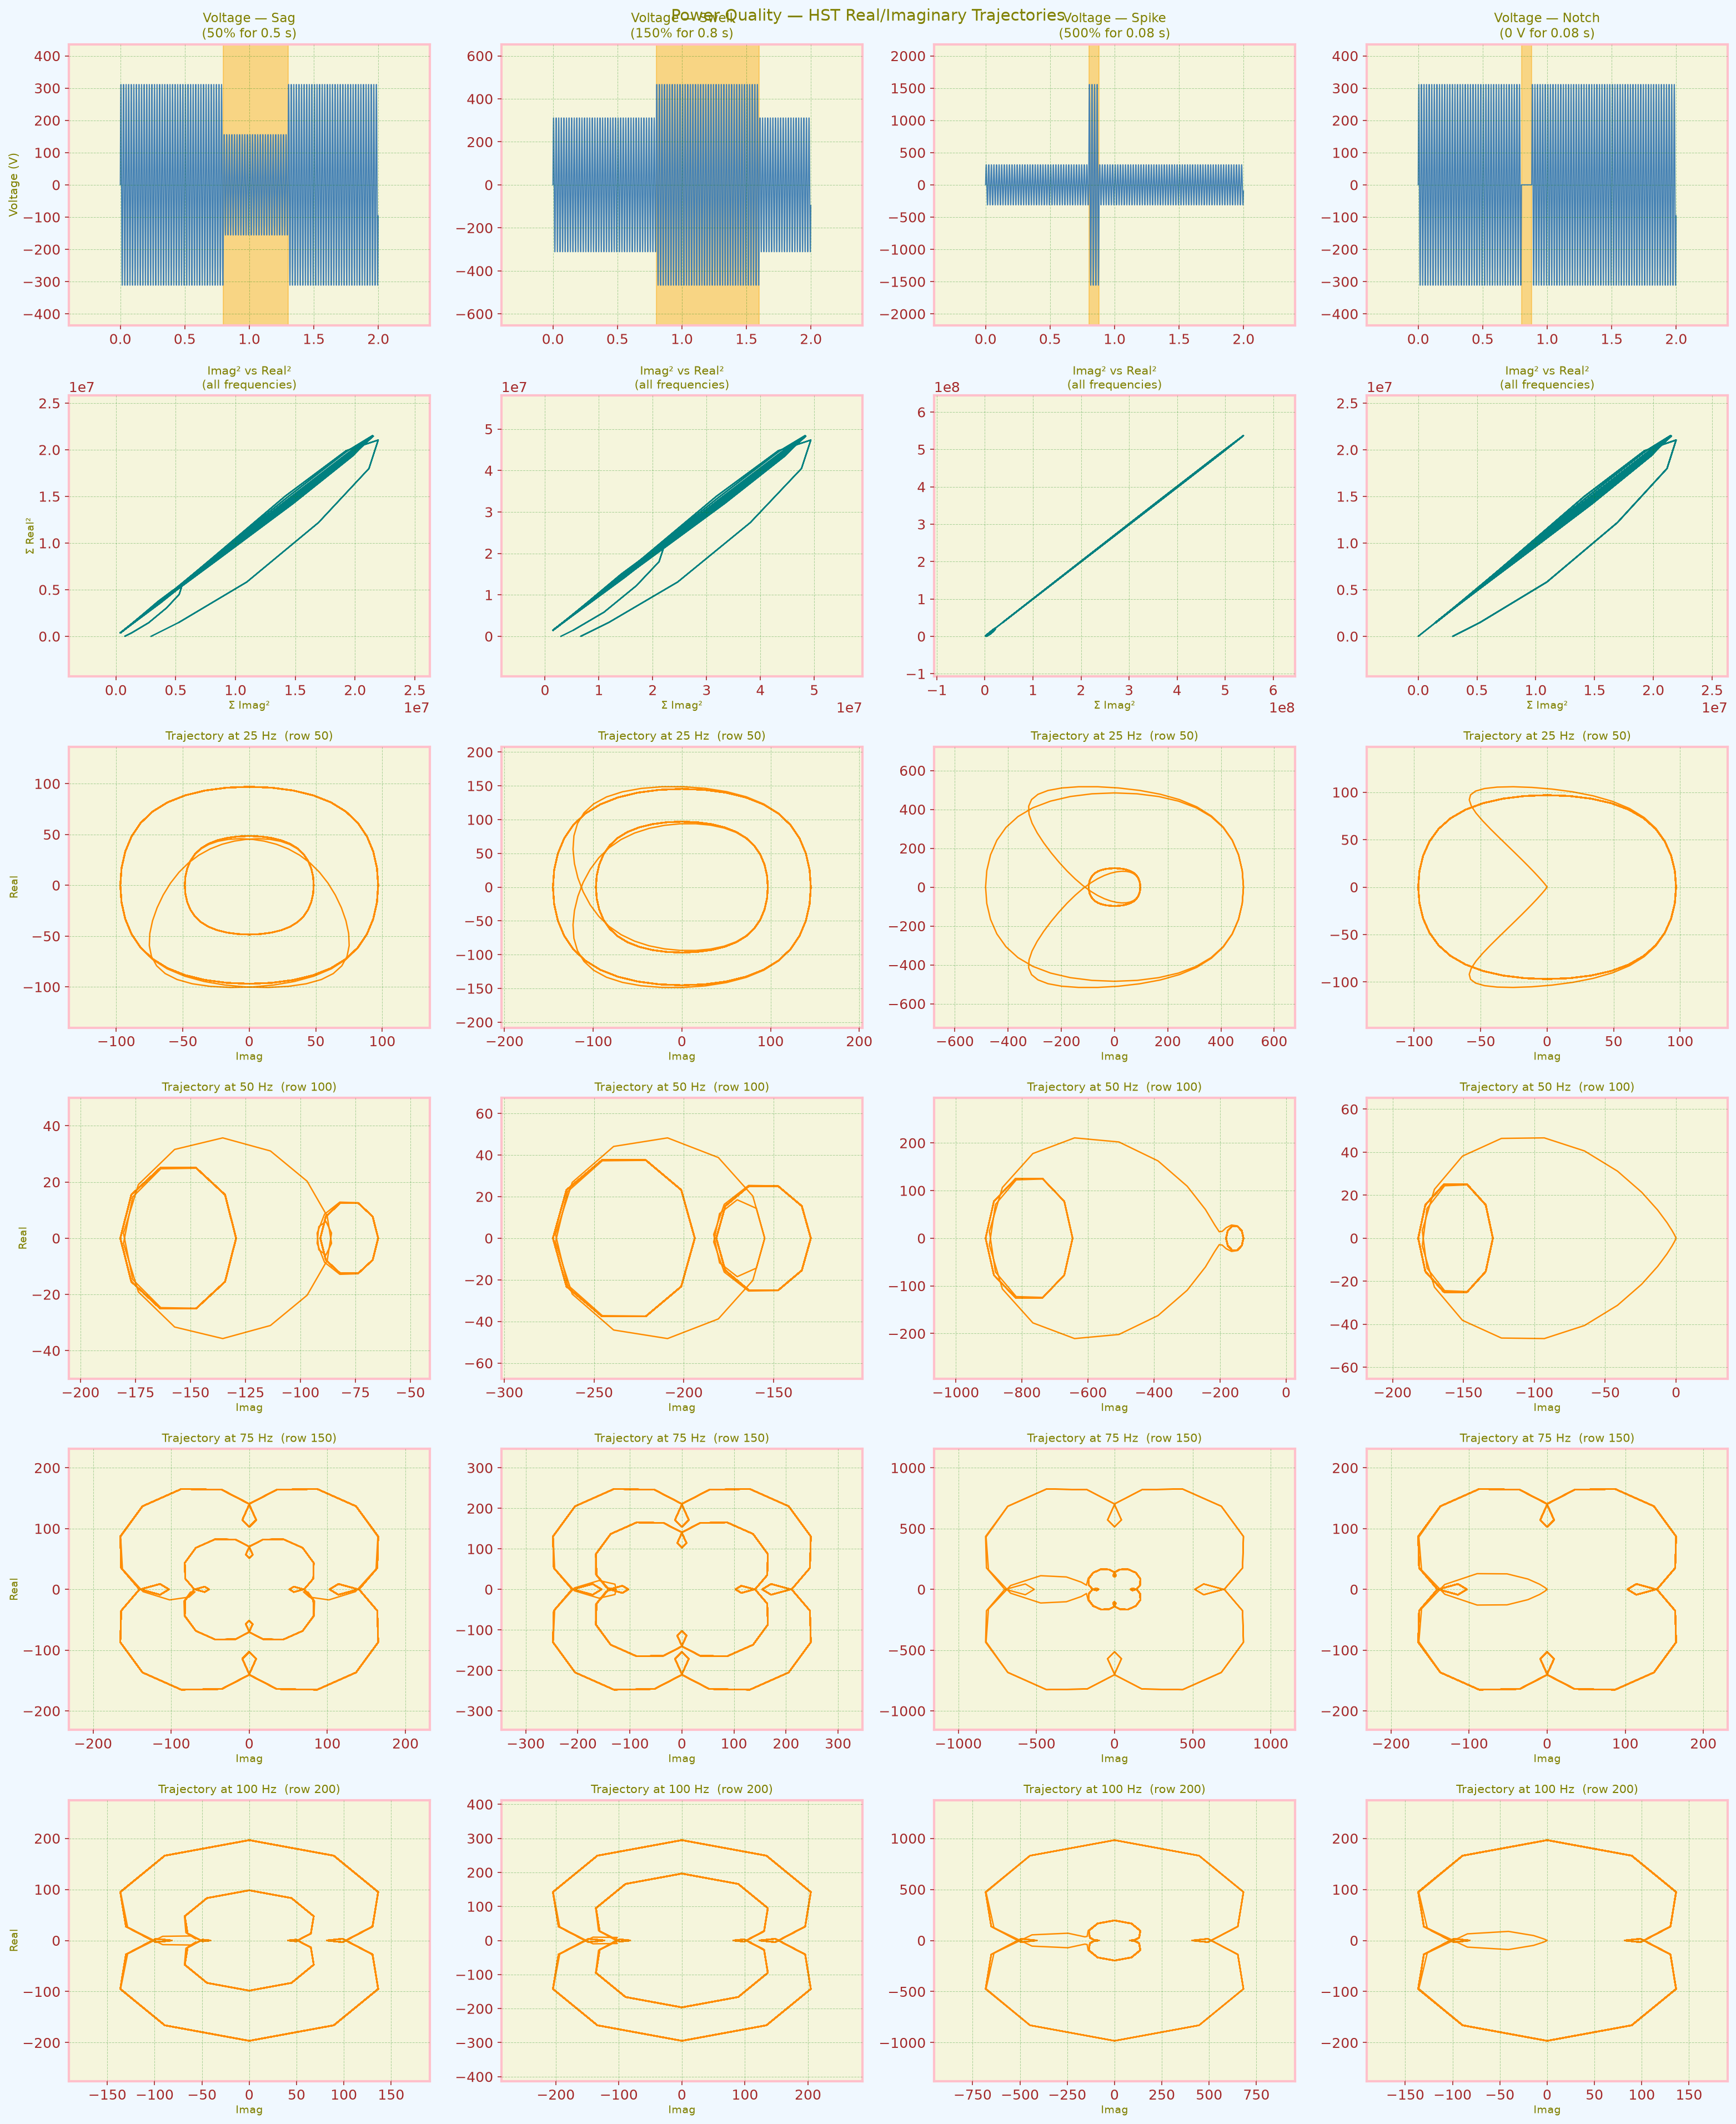

In [ ]:
# With n*dt=2 s: bin k = k/(n*dt) = k/2 Hz → 50 Hz = bin 100
freq_list_hz = [25, 50, 75, 100]
freq_rows    = [int(round(f * n_pq * dt_pq)) for f in freq_list_hz]

fig, axs = plt.subplots(len(freq_rows)+2, len(signals), figsize=(21, 26), sharex=False)
fig.suptitle('Power Quality — HST Real/Imaginary Trajectories', fontsize=14, color='Olive')

for i, (name, signal) in enumerate(signals.items()):
    S = st.fit_transform(t, signal)

    axs[0, i].plot(t, signal, color='steelblue', lw=1.0)
    axs[0, i].set_title(f'Voltage — {name}', fontsize=11)
    axs[0, i].axvspan(*highlight[i], color='orange', alpha=0.4)
    if i == 0:
        axs[0, i].set_ylabel('Voltage (V)', fontsize=10)

    axs[1, i].plot(np.sum(S.imag**2, axis=0), np.sum(S.real**2, axis=0),
                   lw=1.2, color='teal')
    axs[1, i].set_title('Imag² vs Real²\n(all frequencies)', fontsize=10)
    axs[1, i].set_xlabel('Σ Imag²', fontsize=9)
    if i == 0:
        axs[1, i].set_ylabel('Σ Real²', fontsize=9)

    for j, (f_hz, row) in enumerate(zip(freq_list_hz, freq_rows)):
        if row < S.shape[0]:
            axs[j+2, i].plot(S[row, :].imag, S[row, :].real, lw=1.2, color='darkorange')
        axs[j+2, i].set_title(f'Trajectory at {f_hz} Hz  (row {row})', fontsize=10)
        axs[j+2, i].set_xlabel('Imag', fontsize=9)
        if i == 0:
            axs[j+2, i].set_ylabel('Real', fontsize=9)

plt.savefig('power_quality_disturbance_trajectory.png', dpi=150, bbox_inches='tight')
plt.show()

Saved pq_trajectory_animated.gif


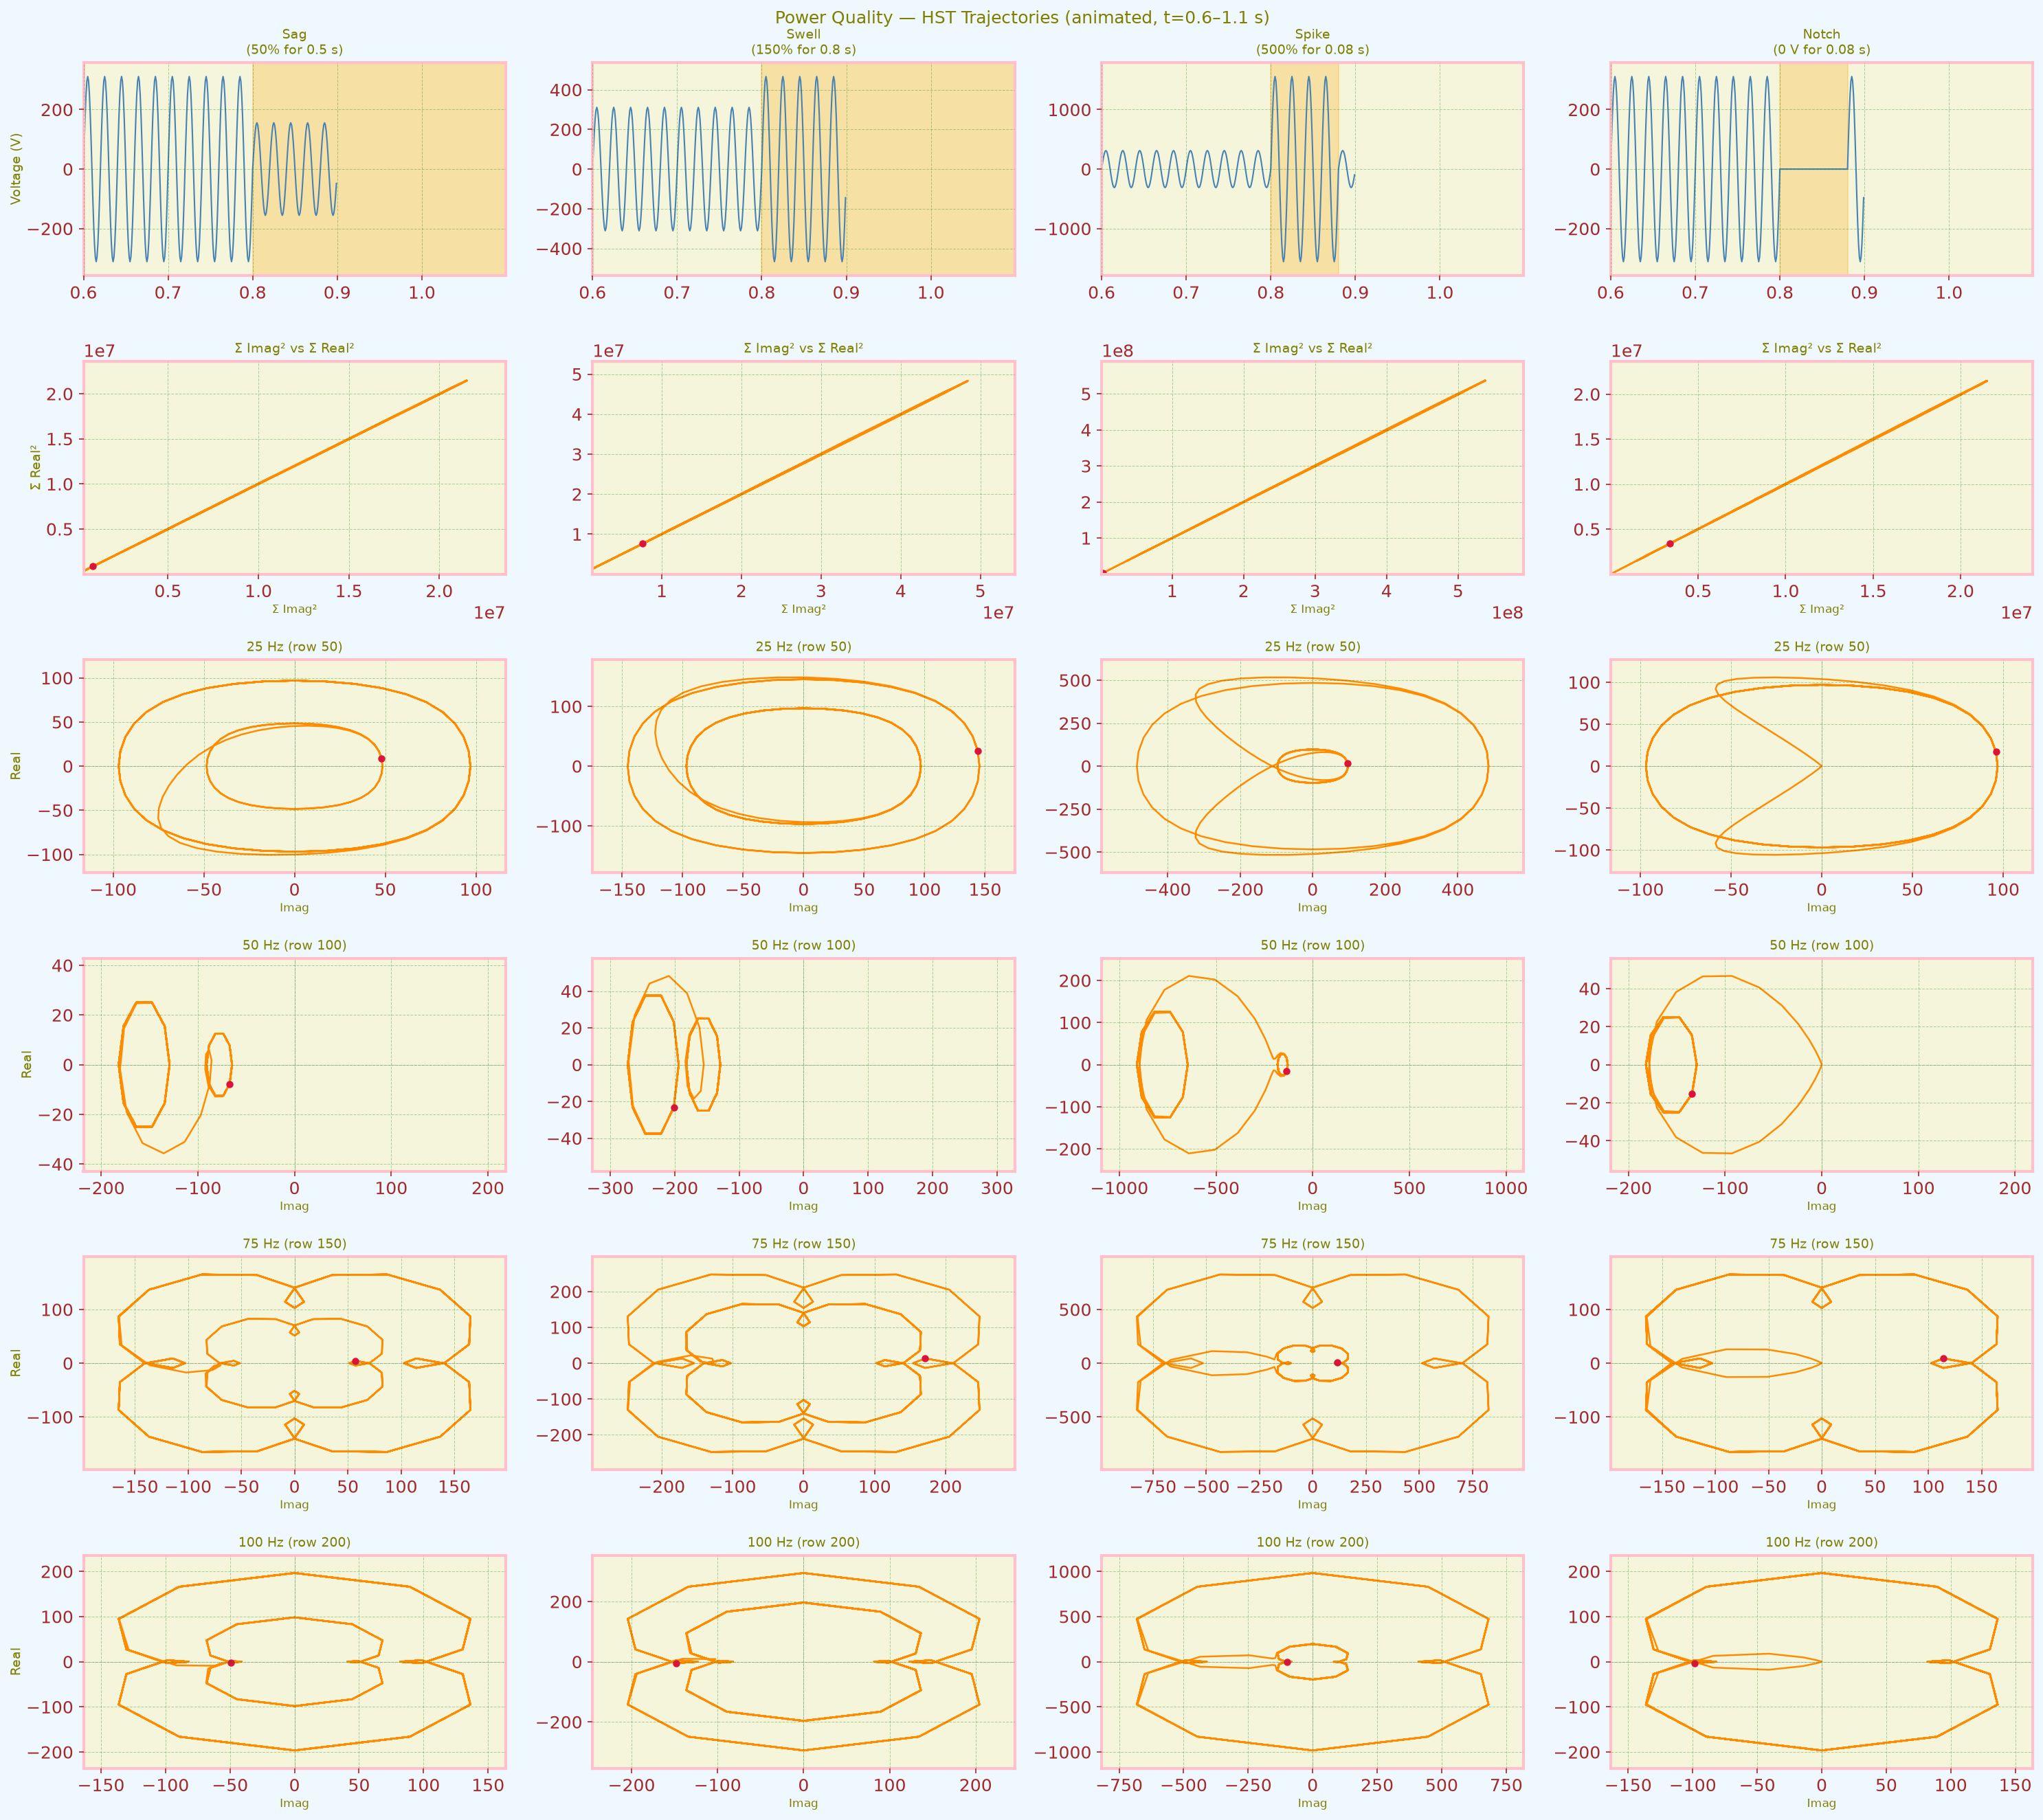

In [ ]:
from matplotlib.animation import FuncAnimation, PillowWriter

# Animate the window around the disturbance onset (t=0.6 → 1.1 s, onset at 0.8 s).
# Slower and focused so the trajectory change at onset is clearly visible.
t_win_start_pq = 0.6
t_win_end_pq   = 1.1
idx_s_pq = int(t_win_start_pq / dt_pq)
idx_e_pq = int(t_win_end_pq   / dt_pq)
t_win_pq = t[idx_s_pq:idx_e_pq]
n_win_pq = len(t_win_pq)

n_frames_pq = 300            # more frames over shorter window = slower
step_pq     = max(1, n_win_pq // n_frames_pq)

n_rows_pq = 2 + len(freq_rows)
fig_pq, axs_pq = plt.subplots(
    n_rows_pq, len(signals),
    figsize=(5 * len(signals), 3 * n_rows_pq),
)
fig_pq.suptitle(
    f'Power Quality — HST Trajectories (animated, t={t_win_start_pq}–{t_win_end_pq} s)',
    color='Olive', fontsize=12,
)

S_pq_all = {name: st.fit_transform(t, sig) for name, sig in signals.items()}

sig_lines_pq  = {}
sum_lines_pq  = {}
freq_lines_pq = {}

for col, (name, sig) in enumerate(signals.items()):
    S = S_pq_all[name]
    sig_win = sig[idx_s_pq:idx_e_pq]

    # ── Row 0: raw voltage ────────────────────────────────────────────────
    ax = axs_pq[0, col]
    ax.set_xlim(t_win_pq[0], t_win_pq[-1])
    ypad = max(abs(sig_win)) * 1.15
    ax.set_ylim(-ypad, ypad)
    ax.set_title(name, fontsize=9)
    onset = highlight[col][0]
    if t_win_start_pq <= onset <= t_win_end_pq:
        ax.axvspan(onset, min(highlight[col][1], t_win_end_pq), color='orange', alpha=0.25)
    if col == 0:
        ax.set_ylabel('Voltage (V)', fontsize=9)
    ln, = ax.plot([], [], color='steelblue', lw=1.0)
    sig_lines_pq[col] = ln

    # ── Row 1: Σ Imag² vs Σ Real² (windowed) ─────────────────────────────
    ax1 = axs_pq[1, col]
    sum_re = np.sum(S.real**2, axis=0)[idx_s_pq:idx_e_pq]
    sum_im = np.sum(S.imag**2, axis=0)[idx_s_pq:idx_e_pq]
    pad = 0.1
    ax1.set_xlim(sum_im.min()*(1-pad), sum_im.max()*(1+pad))
    ax1.set_ylim(sum_re.min()*(1-pad), sum_re.max()*(1+pad))
    ax1.set_title('Σ Imag² vs Σ Real²', fontsize=9)
    ax1.set_xlabel('Σ Imag²', fontsize=8)
    if col == 0:
        ax1.set_ylabel('Σ Real²', fontsize=9)
    ax1.axhline(0, color='grey', lw=0.4, ls=':')
    ax1.axvline(0, color='grey', lw=0.4, ls=':')
    ln1, = ax1.plot([], [], color='teal', lw=1.2)
    dot1, = ax1.plot([], [], 'o', ms=4, color='crimson')
    sum_lines_pq[col] = (ln1, dot1, sum_im, sum_re)

    # ── Rows 2+: frequency trajectories (windowed) ───────────────────────
    for j, (f_hz, row) in enumerate(zip(freq_list_hz, freq_rows)):
        axj = axs_pq[j+2, col]
        if row < S.shape[0]:
            re_j = S[row, idx_s_pq:idx_e_pq].real
            im_j = S[row, idx_s_pq:idx_e_pq].imag
            lim_r = max(abs(re_j))*1.2 or 1.0
            lim_i = max(abs(im_j))*1.2 or 1.0
        else:
            lim_r = lim_i = 1.0
        axj.set_xlim(-lim_i, lim_i)
        axj.set_ylim(-lim_r, lim_r)
        axj.set_title(f'{f_hz} Hz (row {row})', fontsize=9)
        axj.set_xlabel('Imag', fontsize=8)
        if col == 0:
            axj.set_ylabel('Real', fontsize=9)
        axj.axhline(0, color='grey', lw=0.4, ls=':')
        axj.axvline(0, color='grey', lw=0.4, ls=':')
        lnj, = axj.plot([], [], lw=1.2, color='steelblue')
        dotj, = axj.plot([], [], 'o', ms=4, color='crimson')
        freq_lines_pq[(col, j)] = (lnj, dotj, row)

plt.tight_layout()

def _pq_anim_update(frame):
    end = min((frame + 1) * step_pq, n_win_pq)
    artists = []
    for col, (name, sig) in enumerate(signals.items()):
        S = S_pq_all[name]
        onset_abs = highlight[col][0]
        onset_win_idx = int((onset_abs - t_win_start_pq) / dt_pq)
        after_onset = end > onset_win_idx

        sig_win = sig[idx_s_pq:idx_e_pq]
        sig_lines_pq[col].set_data(t_win_pq[:end], sig_win[:end])
        artists.append(sig_lines_pq[col])

        ln1, dot1, sum_im, sum_re = sum_lines_pq[col]
        ln1.set_data(sum_im[:end], sum_re[:end])
        ln1.set_color('darkorange' if after_onset else 'teal')
        dot1.set_data([sum_im[end-1]], [sum_re[end-1]])
        artists += [ln1, dot1]

        for j, (f_hz, row_idx) in enumerate(zip(freq_list_hz, freq_rows)):
            lnj, dotj, row = freq_lines_pq[(col, j)]
            if row < S.shape[0]:
                S_win = S[row, idx_s_pq:idx_e_pq]
                lnj.set_data(S_win[:end].imag, S_win[:end].real)
                lnj.set_color('darkorange' if after_onset else 'steelblue')
                dotj.set_data([S_win[end-1].imag], [S_win[end-1].real])
            artists += [lnj, dotj]
    return artists

anim_pq_full = FuncAnimation(
    fig_pq, _pq_anim_update,
    frames=n_frames_pq, interval=120, blit=True,
)
anim_pq_full.save('./pq_trajectory_animated.gif', writer=PillowWriter(fps=8))
print('Saved pq_trajectory_animated.gif')
plt.show()


### 1.3 Signal configuration comparison — three parameterisations

The same HST vs Morlet spectrogram shown for three different signal setups:

| Config | Sampling | Record | Disturbance window | Key feature |
|--------|----------|--------|--------------------|-------------|
| **A — current notebook** | 1 kHz, 2 s | 0–2 s | 0.8–1.6 s | Well-resolved cycles, easy-to-read Hz axis |
| **B — user example (corrected)** | 1 kHz, 10 s | 0–10 s | 2–5 s | Longer record; same 50 Hz signal, matching user-supplied parameters |
| **C — sub-cycle events** | 10 kHz, 0.2 s | 0–0.2 s | spike/notch < 1 ms | Tests time-frequency resolution at sub-cycle scale |

Config A and B use 50 Hz, 220 V (peak × √2). Config C uses a 200 Hz carrier to keep events clearly above DC.

In [ ]:
# ── Config A: current notebook (already defined above as `signals`) ──────────
# (reuse V_sag, V_swell, V_spike, V_notch from cell 6)
cfg_A = {
    't': t,
    'dt': dt_pq,
    'signals': signals,
    'label': 'A — 1 kHz / 2 s / events at 0.8–1.6 s',
}

# ── Config B: user-supplied parameterisation (corrected sampling) ─────────────
fs_B   = 1000
n_B    = 10 * fs_B          # 10-second record
t_B    = np.arange(n_B) / fs_B
V_m_B  = 220 * np.sqrt(2)
V_c_B  = V_m_B * np.sin(2 * np.pi * 50 * t_B)
cfg_B = {
    't': t_B,
    'dt': 1.0 / fs_B,
    'signals': {
        'Sag\n(50% for 1.5 s)':     np.where((t_B >= 2) & (t_B <= 3.5),  0.5 * V_c_B, V_c_B),
        'Swell\n(150% for 2 s)':    np.where((t_B >= 3) & (t_B <= 5),    1.5 * V_c_B, V_c_B),
        'Spike\n(500% for 0.2 s)':  np.where((t_B >= 2) & (t_B <= 2.2),  5.0 * V_c_B, V_c_B),
        'Notch\n(0 V for 0.3 s)':   np.where((t_B >= 0.6) & (t_B <= 0.9), 0.0 * V_c_B, V_c_B),
    },
    'label': 'B — 1 kHz / 10 s / user example (corrected)',
}

# ── Config C: sub-cycle events (10 kHz, 200 Hz carrier) ──────────────────────
fs_C   = 10_000
n_C    = int(0.2 * fs_C)    # 0.2-second record
t_C    = np.arange(n_C) / fs_C
V_c_C  = 220 * np.sqrt(2) * np.sin(2 * np.pi * 200 * t_C)
cfg_C = {
    't': t_C,
    'dt': 1.0 / fs_C,
    'signals': {
        'Sag\n(50% for 8 ms)':    np.where((t_C >= 0.08) & (t_C <= 0.088),  0.5 * V_c_C, V_c_C),
        'Swell\n(150% for 6 ms)': np.where((t_C >= 0.08) & (t_C <= 0.086),  1.5 * V_c_C, V_c_C),
        'Spike\n(500% for 0.3ms)':np.where((t_C >= 0.08) & (t_C <= 0.0803), 5.0 * V_c_C, V_c_C),
        'Notch\n(0 V for 0.3ms)': np.where((t_C >= 0.08) & (t_C <= 0.0803), 0.0 * V_c_C, V_c_C),
    },
    'label': 'C — 10 kHz / 0.2 s / sub-cycle events',
}

configs = [cfg_A, cfg_B, cfg_C]

# ── Data-quality validation ───────────────────────────────────────────────────
_V_nom = 220 * np.sqrt(2)   # ~311 V peak for both B and C carriers

# Config B: 50 Hz carrier — peak within 1% of 220√2
_peak_B = float(np.abs(V_c_B).max())
assert abs(_peak_B - _V_nom) / _V_nom < 0.01, \
    f"Config B carrier peak {_peak_B:.1f} V deviates >1% from nominal {_V_nom:.1f} V"

# Config B: Nyquist margin — fs 1 kHz >> 50 Hz (ratio 20×, needs ≥ 10×)
assert fs_B / 50 >= 10, f"Config B: fs/f0={fs_B/50:.0f} — insufficient Nyquist margin"

# Config C: 200 Hz carrier — peak within 1% of 220√2
_peak_C = float(np.abs(V_c_C).max())
assert abs(_peak_C - _V_nom) / _V_nom < 0.01, \
    f"Config C carrier peak {_peak_C:.1f} V deviates >1% from nominal {_V_nom:.1f} V"

# Config C: Nyquist margin — fs 10 kHz >> 200 Hz (ratio 50×, needs ≥ 10×)
assert fs_C / 200 >= 10, f"Config C: fs/f0={fs_C/200:.0f} — insufficient Nyquist margin"

# All configs: no NaN or Inf in any signal array
for _cfg in configs:
    for _name, _sig in _cfg['signals'].items():
        assert np.isfinite(_sig).all(), \
            f"Config {_cfg['label']!r} — {_name!r} contains NaN/Inf"

# Config B sag amplitude ≤ nominal; swell amplitude ≥ 150% of nominal
_sag_B = list(cfg_B['signals'].values())[0]
_swl_B = list(cfg_B['signals'].values())[1]
assert float(np.abs(_sag_B).max()) <= _V_nom * 1.01, \
    "Config B sag exceeds nominal amplitude"
assert float(np.abs(_swl_B).max()) >= _V_nom * 1.49, \
    "Config B swell does not reach ≥150% amplitude"

# Config C sag amplitude ≤ nominal; swell amplitude ≥ 150% of nominal
_sag_C = list(cfg_C['signals'].values())[0]
_swl_C = list(cfg_C['signals'].values())[1]
assert float(np.abs(_sag_C).max()) <= _V_nom * 1.01, \
    "Config C sag exceeds nominal amplitude"
assert float(np.abs(_swl_C).max()) >= _V_nom * 1.49, \
    "Config C swell does not reach ≥150% amplitude"

print("Config data-quality checks passed.")
print('Configs ready:', [c["label"] for c in configs])


Saved ./pq_comparison_config_a_notebook.png


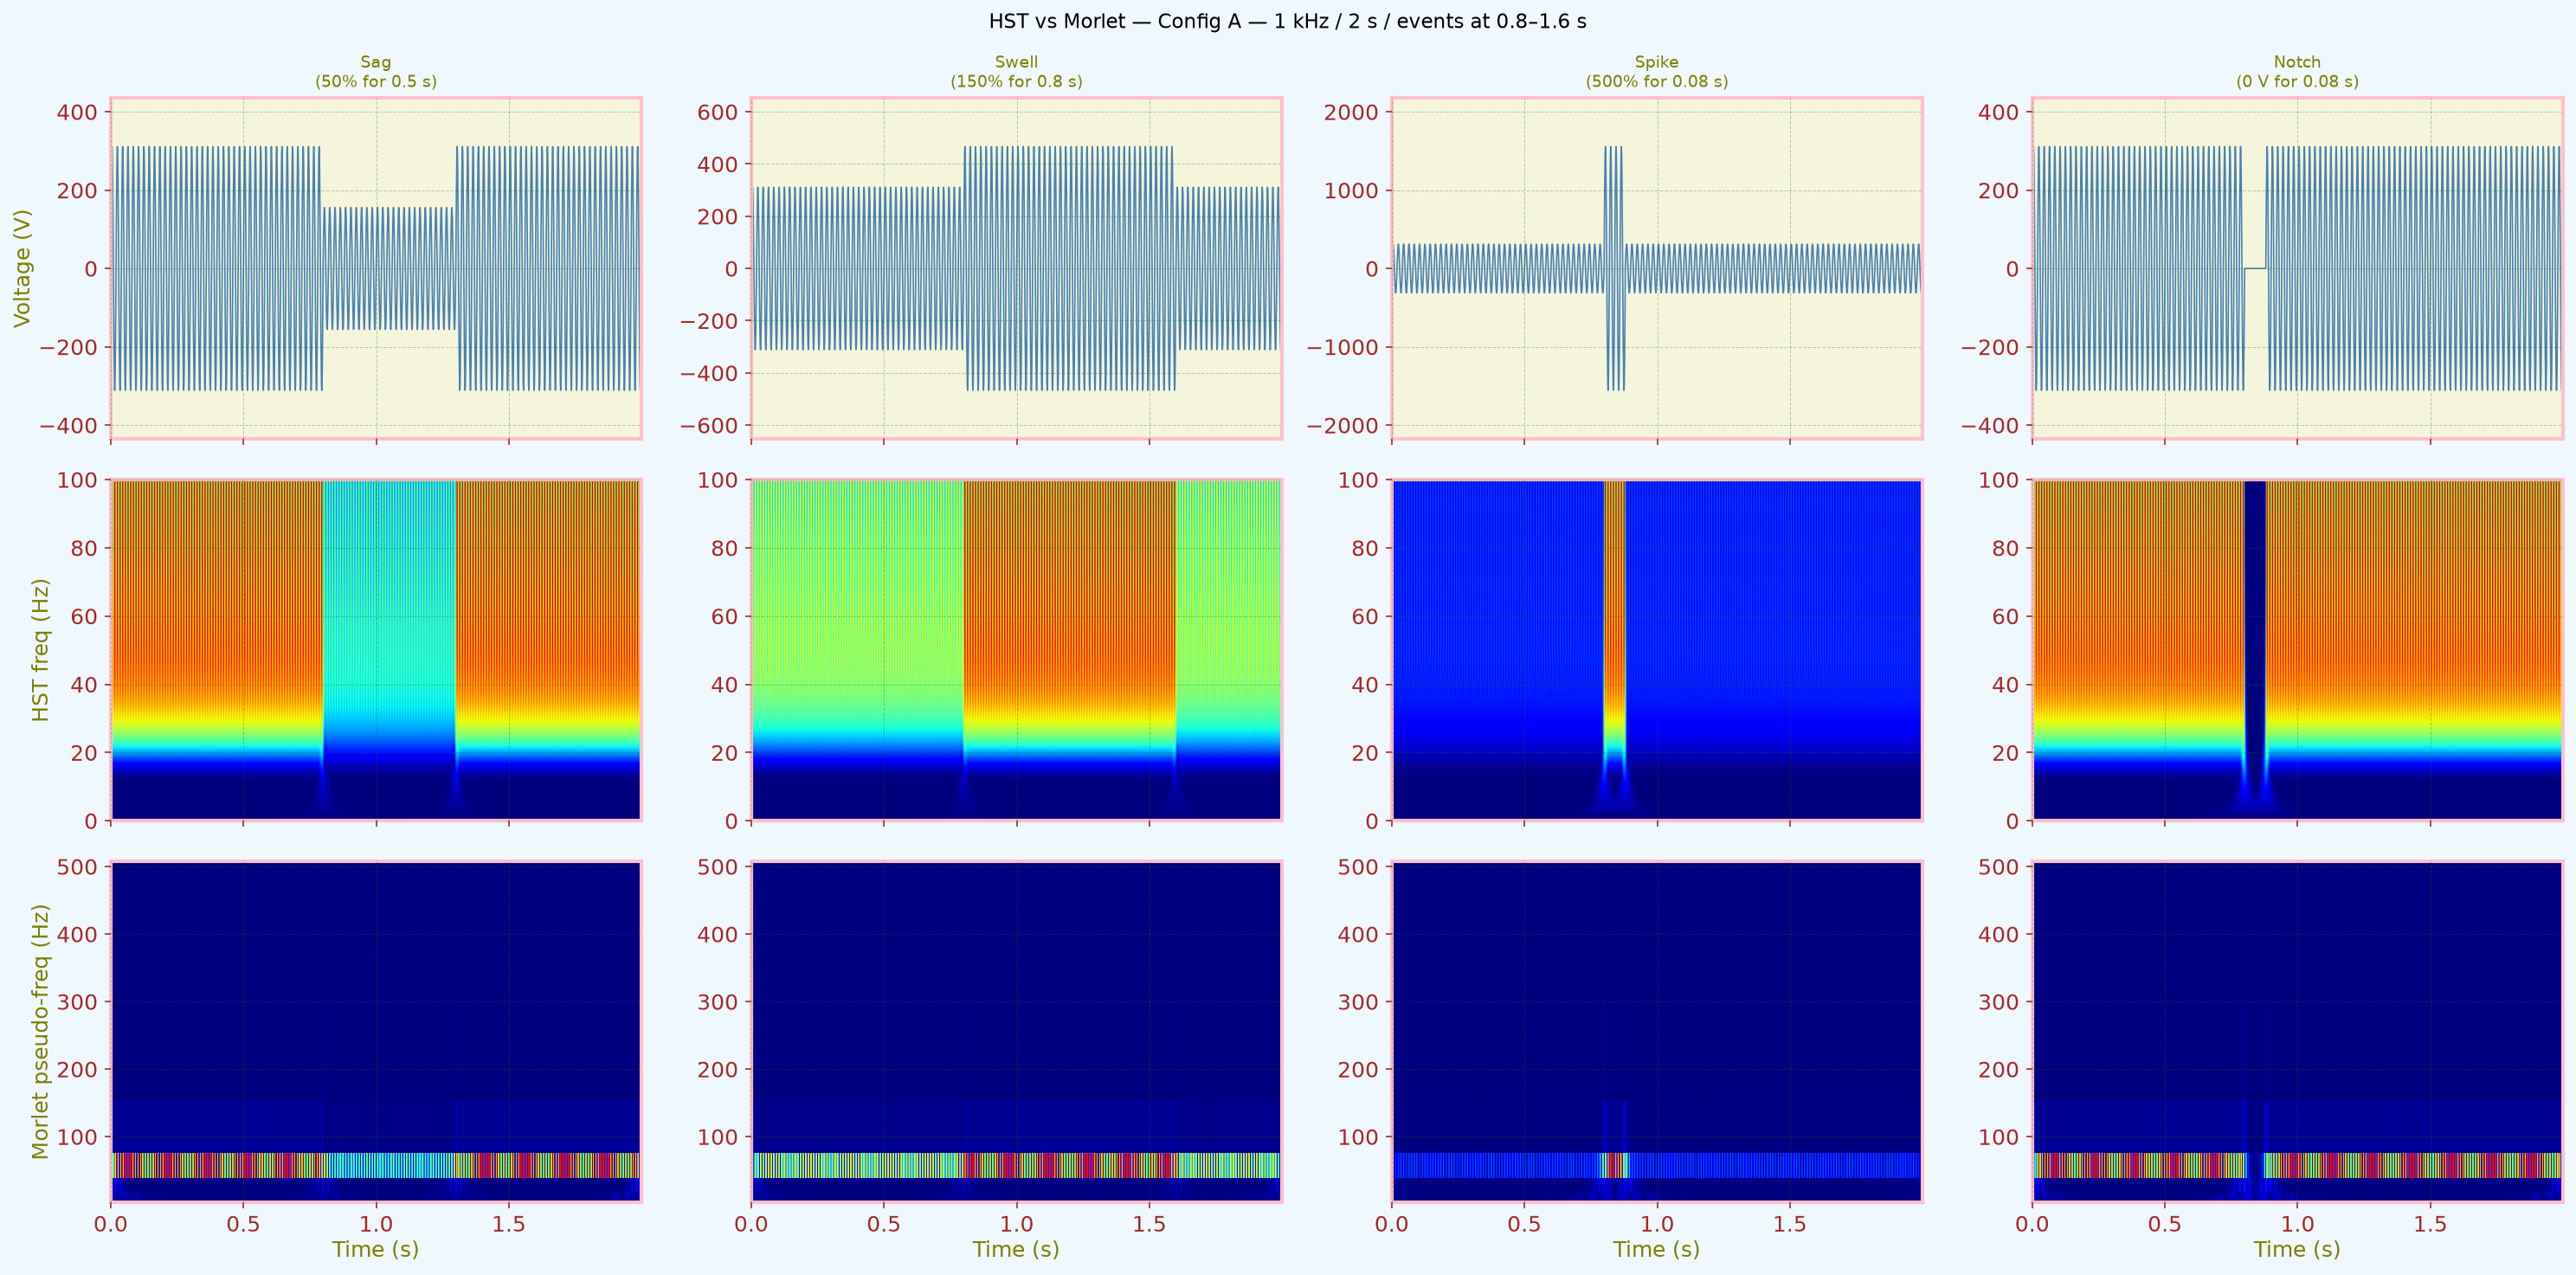

Saved ./pq_comparison_config_b_user.png


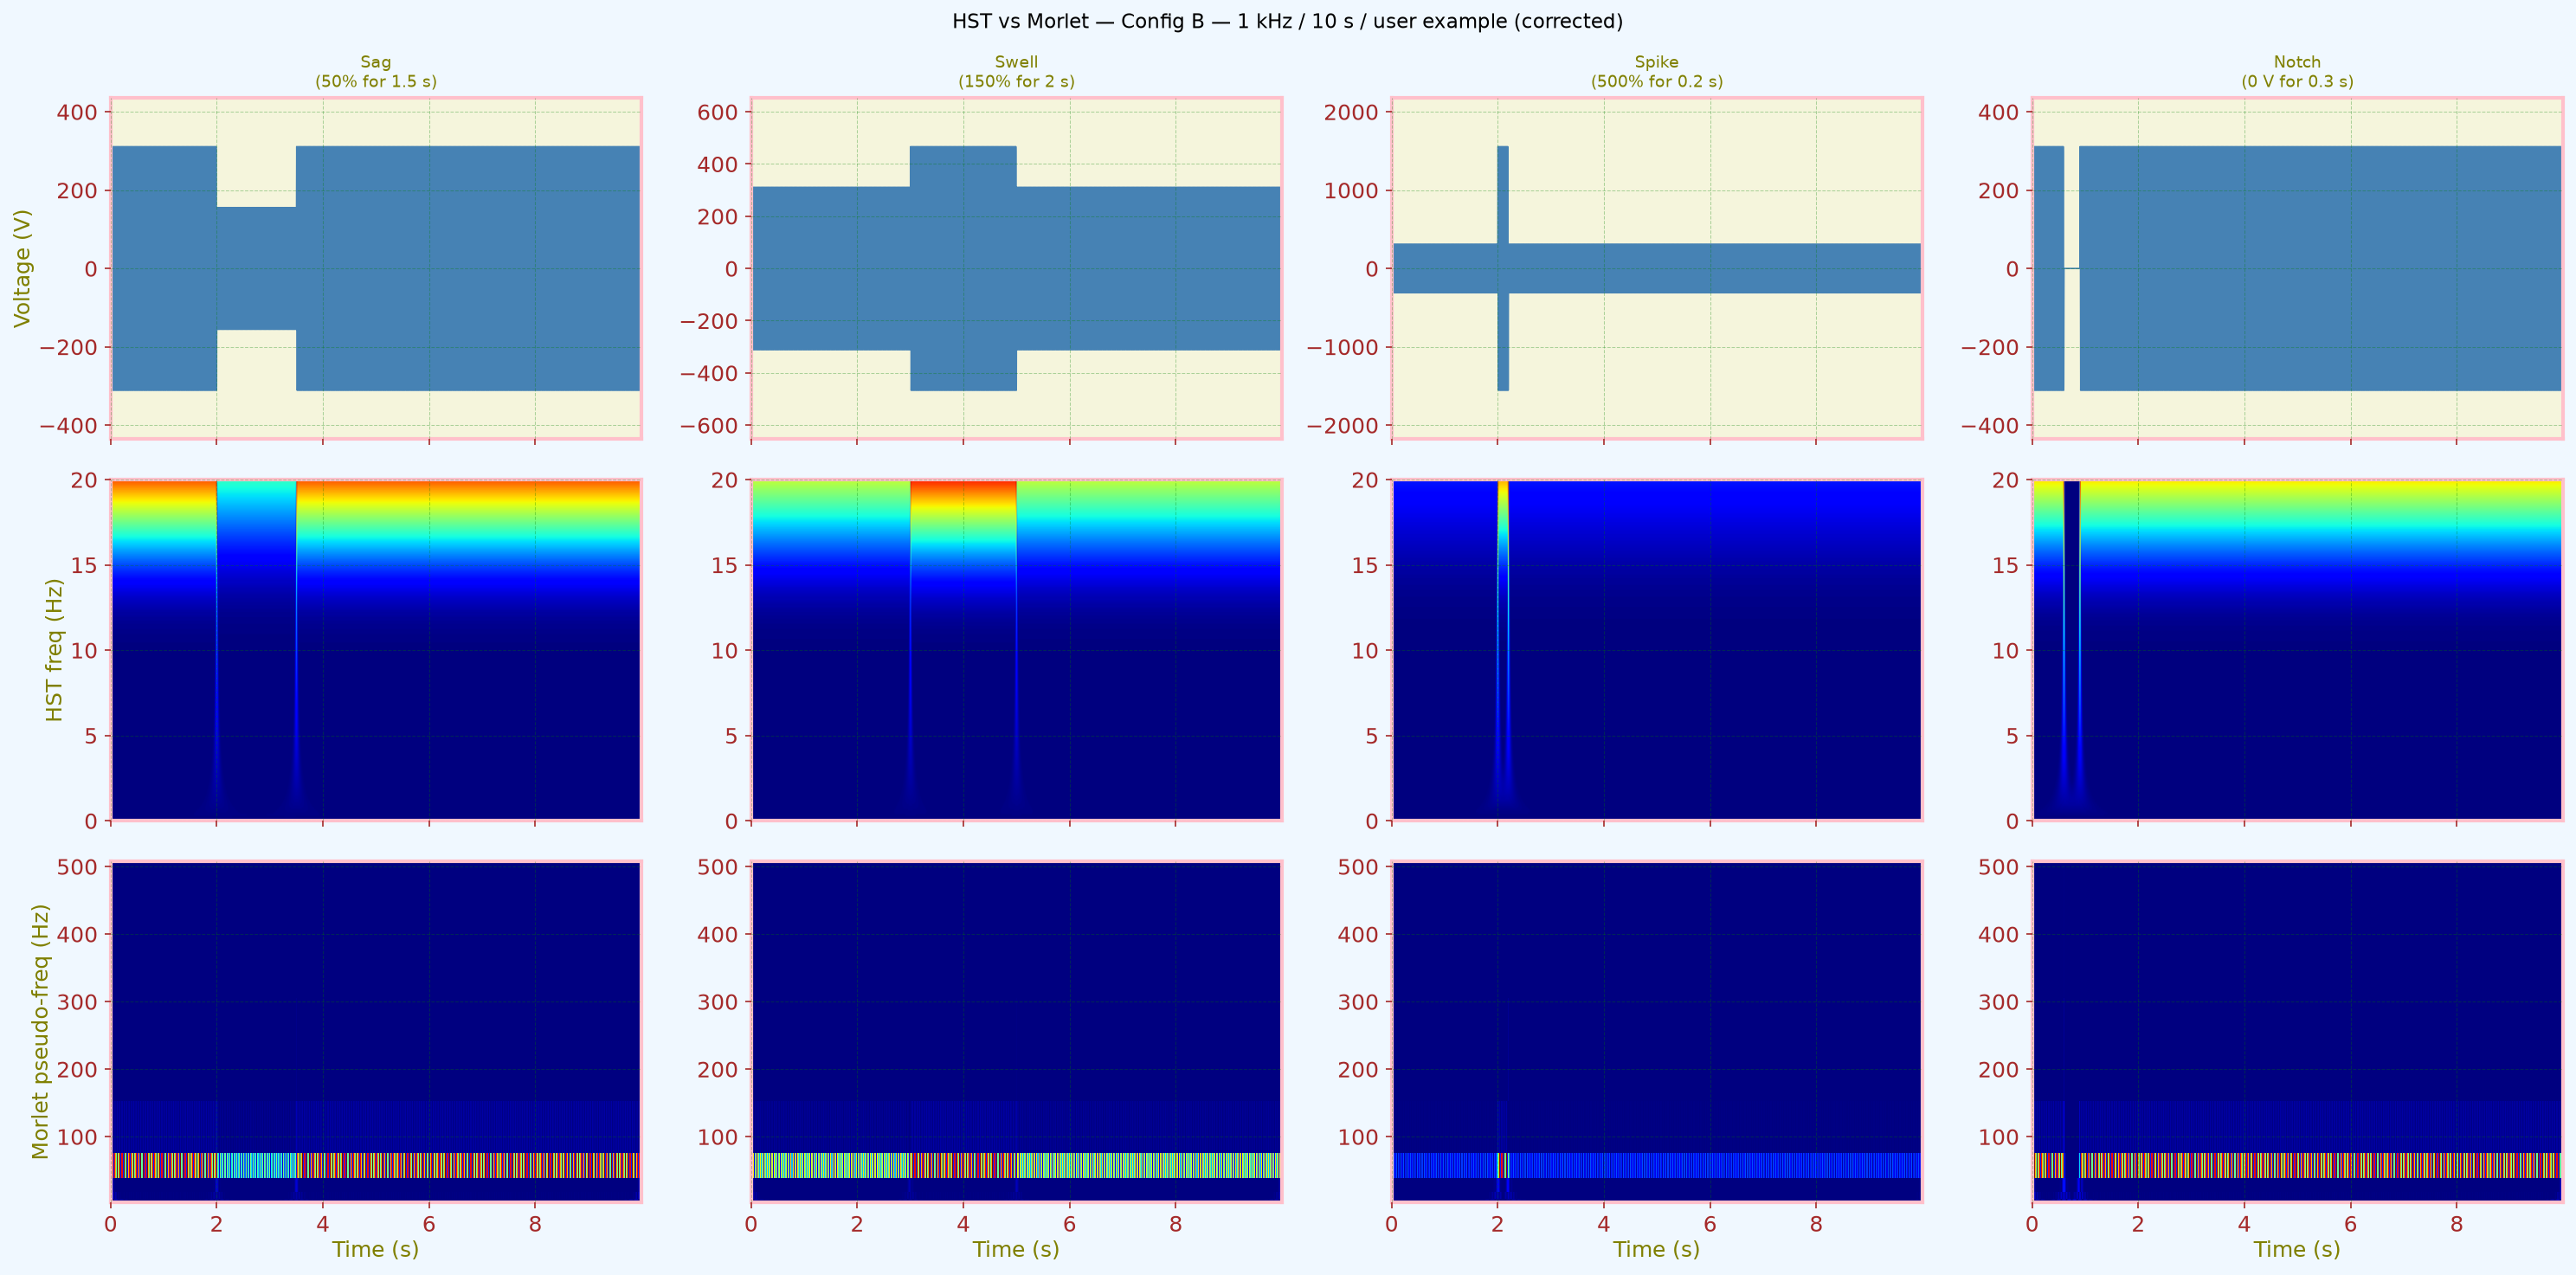

Saved ./pq_comparison_config_c_subcycle.png


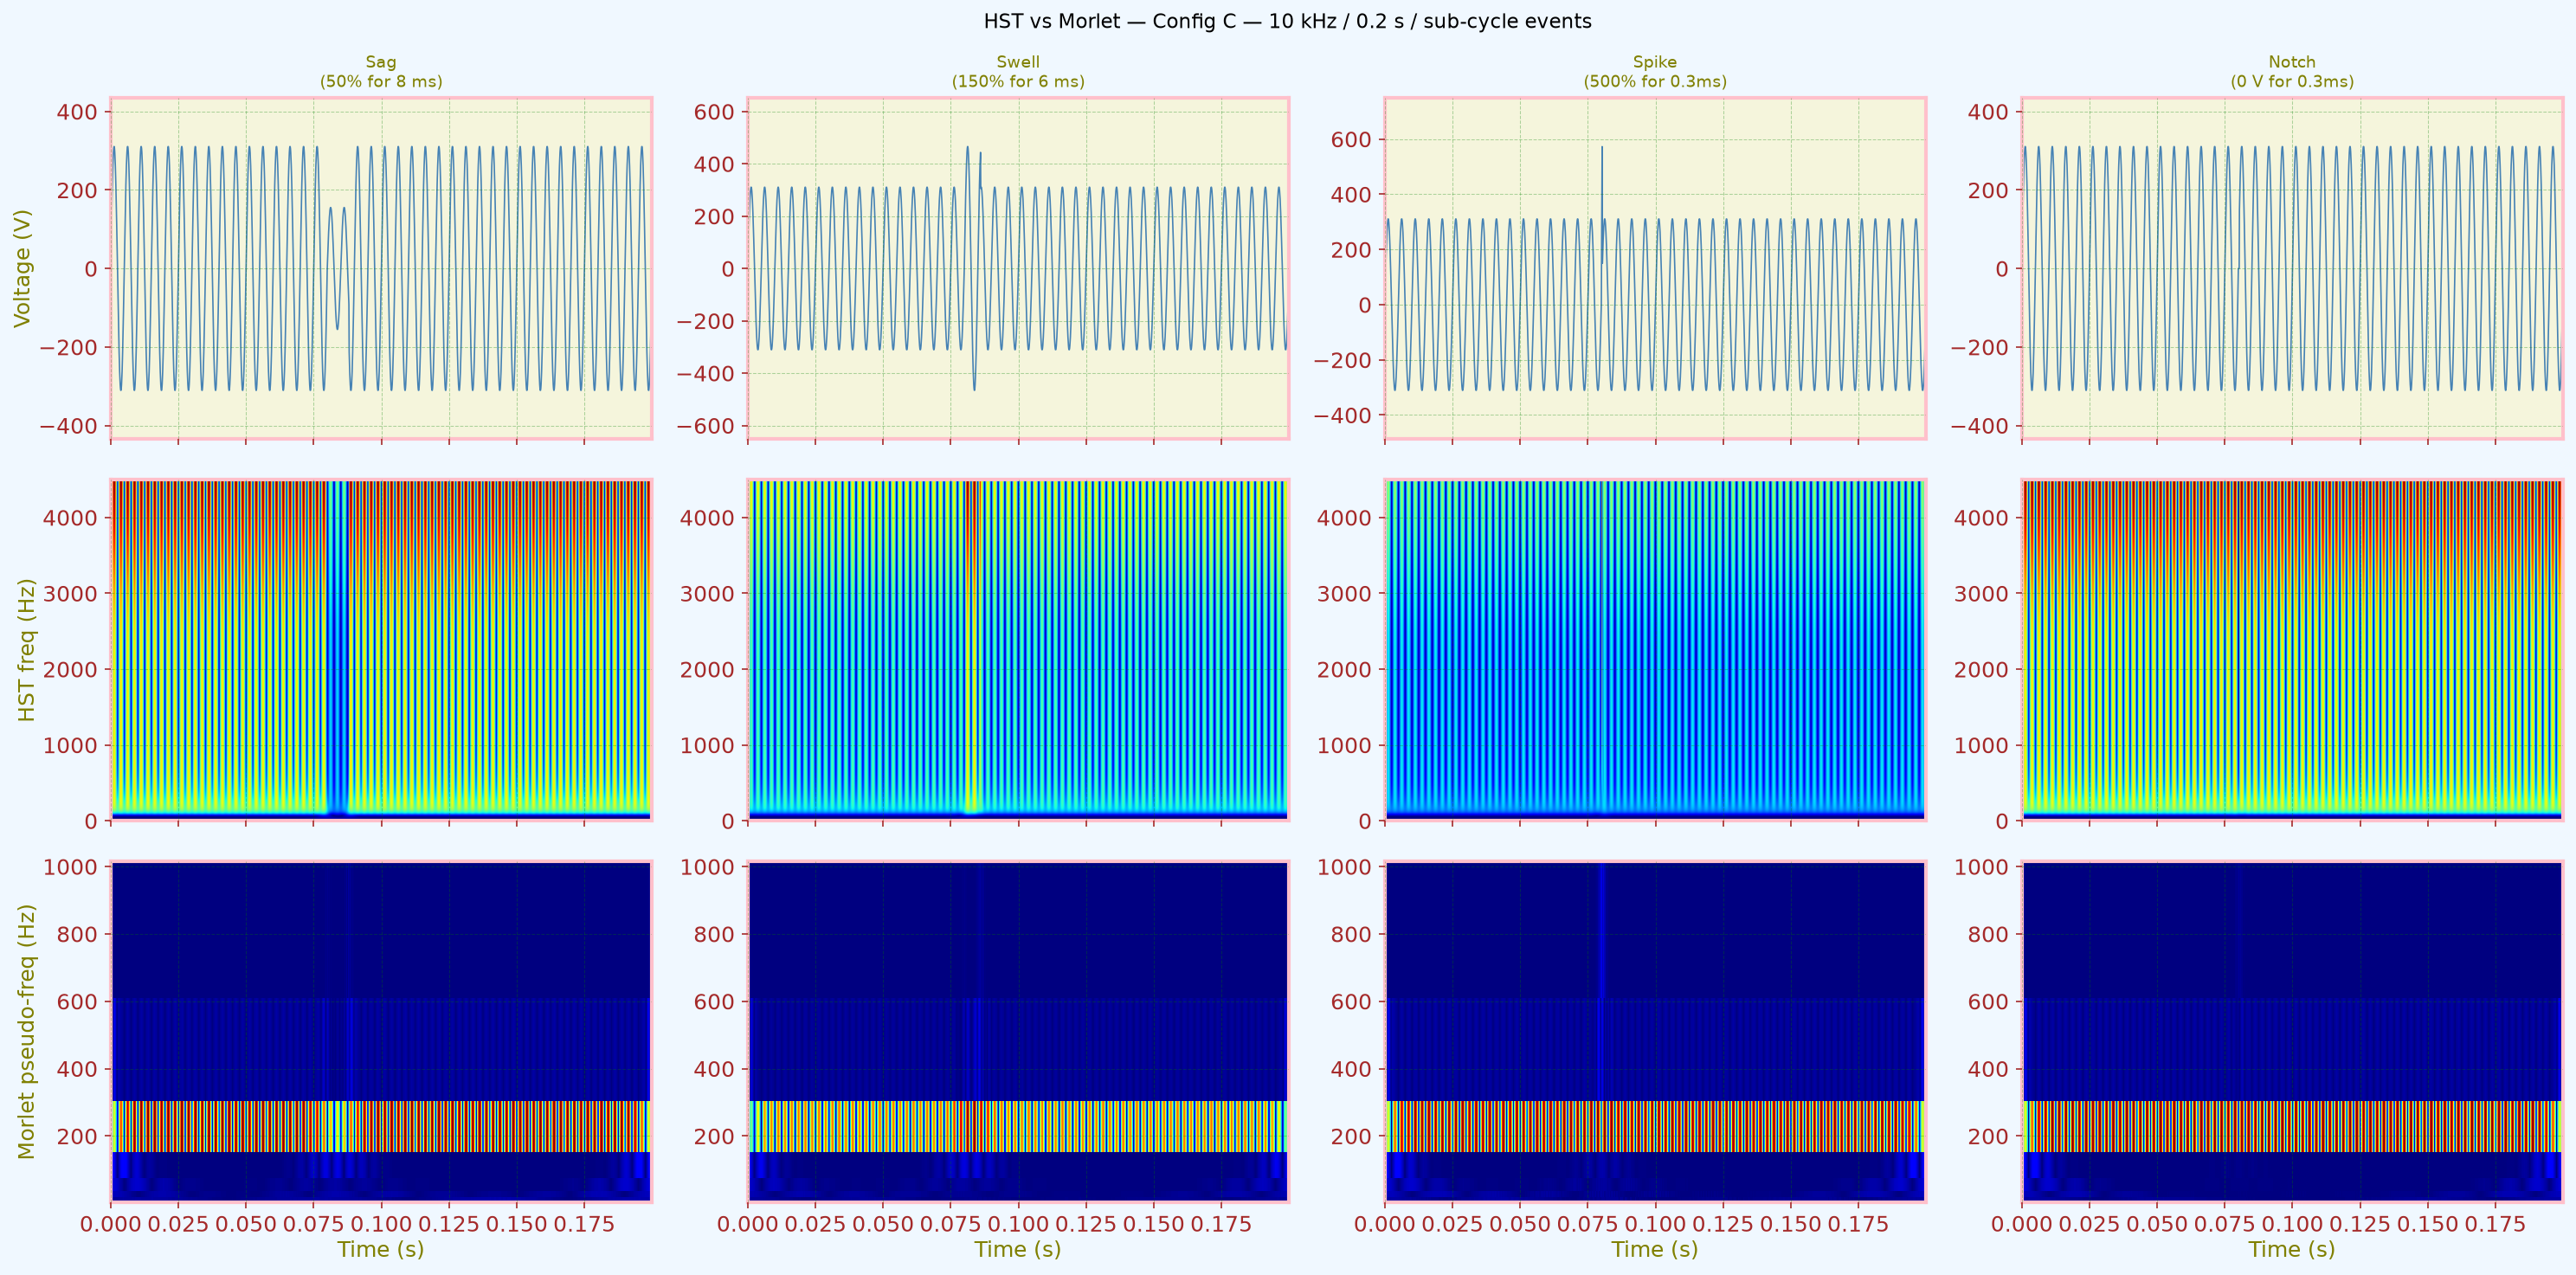

In [ ]:
slug_map = {'A': 'config_a_notebook', 'B': 'config_b_user', 'C': 'config_c_subcycle'}

for cfg in configs:
    t_c   = cfg['t']
    dt_c  = cfg['dt']
    sigs  = cfg['signals']
    label = cfg['label']
    n_c   = len(t_c)
    slug  = slug_map[label[0]]  # first char is A / B / C

    st_c       = HSTransform()
    freqs_hst  = st_c.frequency_axis(n_c, dt_c)
    freq_cap_c = min(int(1 / (2 * dt_c) * 0.4), 900)  # show up to 40% of Nyquist

    # Morlet scales
    center_hz = np.array([5, 10, 25, 50, 100, 200, 400, 800])
    center_hz = center_hz[center_hz < 1 / (2 * dt_c)]
    scales_c  = np.sort((0.8125 / (center_hz * dt_c)).astype(int))[::-1]
    scales_c  = np.unique(np.clip(scales_c, 2, 2000))[::-1]

    fig, axs = plt.subplots(3, len(sigs), figsize=(5 * len(sigs), 10), sharex=True)
    fig.suptitle(f'HST vs Morlet — Config {label}', fontsize=11)

    for col, (name, sig) in enumerate(sigs.items()):
        # Row 0: raw signal
        axs[0, col].plot(t_c, sig, color='steelblue', lw=0.8)
        axs[0, col].set_title(name, fontsize=9)
        if col == 0:
            axs[0, col].set_ylabel('Voltage (V)')

        # Row 1: HST spectrogram (imshow, linear Hz axis)
        S = st_c.fit_transform(t_c, sig, maxf=freq_cap_c)
        axs[1, col].imshow(
            np.abs(S), aspect='auto', origin='lower', cmap='jet',
            extent=[t_c[0], t_c[-1], freqs_hst[0], freqs_hst[freq_cap_c]],
        )
        if col == 0:
            axs[1, col].set_ylabel('HST freq (Hz)')

        # Row 2: Morlet CWT (pcolormesh, non-uniform Hz axis)
        coeffs, freqs_cwt = pywt.cwt(sig, scales_c, 'morl', sampling_period=dt_c)
        axs[2, col].pcolormesh(t_c, freqs_cwt, np.abs(coeffs), cmap='jet', shading='auto')
        if col == 0:
            axs[2, col].set_ylabel('Morlet pseudo-freq (Hz)')
        axs[2, col].set_xlabel('Time (s)')

    plt.tight_layout()
    # Save to img/ alongside the other example figures
    img_path = f'./pq_comparison_{slug}.png'
    fig.savefig(img_path, dpi=100, bbox_inches='tight')
    print(f'Saved {img_path}')
    plt.show()


---
## Part 2 — Power System Fault Analysis

Synthetic 3-phase current signals (Ia, Ib, Ic) for four fault scenarios:

| Case | Description |
|---|---|
| Healthy | Balanced 3-phase, no fault |
| SLGF A | Single line-to-ground, Phase A |
| DLGF A-B | Double line-to-ground, Phases A and B |
| 3-phase | Symmetric three-phase fault |

Source: `fault_analysis.ipynb` (synthetic equivalents — original required `test_fault_dataset.csv`)

In [ ]:
# Endpoint-exclusive: dt=0.001 s, n*dt=1.0 s → bin k = k Hz exactly
fs_fault    = 1000
n_fault     = 1000
t_fault     = np.arange(n_fault) / fs_fault
dt_fault    = 1.0 / fs_fault
f0          = 50
I_peak      = 500
fault_start = int(0.4 * n_fault)
t0_fault    = t_fault[fault_start]

def make_3phase(t, peak=I_peak):
    Ia = peak * np.sin(2 * np.pi * f0 * t)
    Ib = peak * np.sin(2 * np.pi * f0 * t - 2*np.pi/3)
    Ic = peak * np.sin(2 * np.pi * f0 * t + 2*np.pi/3)
    return Ia, Ib, Ic

Ia0, Ib0, Ic0 = make_3phase(t_fault)

def hf_burst(t, t0, f_hf=200, decay=20, amp=0.6):
    """Transient HF burst at fault inception (capacitive / inductive line effect)."""
    dt = t - t0
    return amp * I_peak * np.where(dt >= 0, np.exp(-decay*dt)*np.sin(2*np.pi*f_hf*dt), 0.0)

# ── Physical fault models ─────────────────────────────────────────────────────
# In all cases: currents are measured at the source / protection relay point.
# A bolted fault increases fault current (limited only by source impedance).
# Pre-fault: balanced 3-phase at I_peak. Post-fault: fault phases carry
# elevated current; unfaulted phases are perturbed by zero-sequence coupling.

# SLGF — Phase A to ground only
# · Ia: high fault current (~2.5×) + HF inception transient
# · Ib, Ic: unfaulted; small rise (~15%) from zero-sequence coupling
Ia_slgf = np.where(t_fault >= t0_fault, 2.5, 1.0)*Ia0 + hf_burst(t_fault, t0_fault, f_hf=150, decay=25)
Ib_slgf = np.where(t_fault >= t0_fault, 1.15, 1.0)*Ib0
Ic_slgf = np.where(t_fault >= t0_fault, 1.15, 1.0)*Ic0

# DLGF — Phases A and B to ground
# · Ia, Ib: both carry fault current (~2×) + HF inception transients
# · Ic: elevated return current through ground (~1.8×); slightly different HF
Ia_dlgf = np.where(t_fault >= t0_fault, 2.0, 1.0)*Ia0 + hf_burst(t_fault, t0_fault, f_hf=200, decay=20)
Ib_dlgf = np.where(t_fault >= t0_fault, 2.0, 1.0)*Ib0 + hf_burst(t_fault, t0_fault, f_hf=200, decay=18)
Ic_dlgf = np.where(t_fault >= t0_fault, 1.8, 1.0)*Ic0  # return current through ground

# 3-Phase — symmetric bolted fault (A-B-C)
# · All phases carry equal high fault current (~3×) + same HF burst amplitude/decay
# · Post-fault waveform remains perfectly balanced (same scale, same decay)
Ia_3ph = np.where(t_fault >= t0_fault, 3.0, 1.0)*Ia0 + hf_burst(t_fault, t0_fault, f_hf=250, decay=15)
Ib_3ph = np.where(t_fault >= t0_fault, 3.0, 1.0)*Ib0 + hf_burst(t_fault, t0_fault, f_hf=250, decay=15)
Ic_3ph = np.where(t_fault >= t0_fault, 3.0, 1.0)*Ic0 + hf_burst(t_fault, t0_fault, f_hf=250, decay=15)

fault_data = {
    'Healthy\n(No Fault)':    {'Ia': Ia0,     'Ib': Ib0,     'Ic': Ic0},
    'SLGF\n(Phase A)':        {'Ia': Ia_slgf, 'Ib': Ib_slgf, 'Ic': Ic_slgf},
    'DLGF\n(Phase A-B)':      {'Ia': Ia_dlgf, 'Ib': Ib_dlgf, 'Ic': Ic_dlgf},
    '3-Phase Fault\n(A-B-C)': {'Ia': Ia_3ph,  'Ib': Ib_3ph,  'Ic': Ic_3ph},
}

# ── Data-quality validation ───────────────────────────────────────────────────
# Check each fault scenario against expected physical properties before proceeding.
def rms(x): return float(np.sqrt(np.mean(x**2)))

pre  = slice(0, fault_start)
post = slice(fault_start, None)
tol  = 0.02   # 2% relative tolerance for balance checks

errors = []
for name, phases in fault_data.items():
    Ia, Ib, Ic = phases['Ia'], phases['Ib'], phases['Ic']

    # 1. No NaN or Inf in any phase
    for ph_name, ph in zip('ABC', [Ia, Ib, Ic]):
        if not np.isfinite(ph).all():
            errors.append(f'{name}: Phase {ph_name} contains NaN/Inf')

    # 2. Pre-fault: all three phases balanced (equal RMS, within 2%)
    rms_pre = [rms(ph[pre]) for ph in [Ia, Ib, Ic]]
    mean_rms = np.mean(rms_pre)
    for ph_name, r in zip('ABC', rms_pre):
        if abs(r - mean_rms) / mean_rms > tol:
            errors.append(f'{name}: pre-fault Phase {ph_name} RMS {r:.1f} not balanced '
                          f'(mean={mean_rms:.1f}, deviation={abs(r-mean_rms)/mean_rms:.3f})')

    # 3. Pre-fault: phase angles 120° apart (cross-correlation peak at ±T/3)
    T_samples = int(fs_fault / f0)   # samples per cycle
    shift_expected = T_samples // 3  # 120° = T/3
    corr_ab = np.correlate(Ia[pre], Ib[pre], mode='full')
    peak_shift = int(np.argmax(corr_ab) - (len(Ia[pre]) - 1))
    if abs(abs(peak_shift) - shift_expected) > 2:
        errors.append(f'{name}: pre-fault A-B phase shift {peak_shift} samples '
                      f'(expected ±{shift_expected})')

    # 4. Fault-type specific post-fault checks
    rms_post = [rms(ph[post]) for ph in [Ia, Ib, Ic]]
    if name == 'Healthy\n(No Fault)':
        # All phases stay balanced post-fault (no fault)
        mean_post = np.mean(rms_post)
        for ph_name, r in zip('ABC', rms_post):
            if abs(r - mean_post) / mean_post > tol:
                errors.append(f'{name}: Phase {ph_name} not balanced ({r:.1f} vs mean {mean_post:.1f})')

    elif 'SLGF' in name:
        # Ia post-fault RMS >> Ib post-fault RMS (Ia is faulted, Ib/Ic unfaulted)
        if not (rms_post[0] > 1.5 * rms_post[1]):
            errors.append(f'{name}: Ia post-fault RMS ({rms_post[0]:.1f}) should be '
                          f'> 1.5× Ib ({rms_post[1]:.1f})')
        # Ib and Ic stay close to each other (both unfaulted)
        if abs(rms_post[1] - rms_post[2]) / max(rms_post[1], rms_post[2]) > 0.15:
            errors.append(f'{name}: Ib/Ic post-fault RMS should be similar '
                          f'(Ib={rms_post[1]:.1f}, Ic={rms_post[2]:.1f})')

    elif 'DLGF' in name:
        # Ia ≈ Ib post-fault (both faulted), Ic elevated above pre-fault RMS
        if abs(rms_post[0] - rms_post[1]) / max(rms_post[0], rms_post[1]) > 0.2:
            errors.append(f'{name}: Ia and Ib should have similar post-fault RMS '
                          f'(Ia={rms_post[0]:.1f}, Ib={rms_post[1]:.1f})')
        if rms_post[2] < rms_pre[2] * 1.2:
            errors.append(f'{name}: Ic post-fault RMS ({rms_post[2]:.1f}) should be '
                          f'> 1.2× pre-fault ({rms_pre[2]:.1f})')

    elif '3-Phase' in name:
        # All three post-fault RMS equal (symmetric fault)
        mean_post = np.mean(rms_post)
        for ph_name, r in zip('ABC', rms_post):
            if abs(r - mean_post) / mean_post > 0.15:
                errors.append(f'{name}: 3-phase fault should be symmetric '
                              f'(Phase {ph_name} RMS={r:.1f}, mean={mean_post:.1f})')
        # Post-fault RMS should exceed pre-fault (higher fault current)
        if mean_post < mean_rms * 1.5:
            errors.append(f'{name}: post-fault RMS ({mean_post:.1f}) should exceed '
                          f'pre-fault ({mean_rms:.1f}) by ≥1.5×')

if errors:
    for e in errors:
        print(f'  FAIL: {e}')
    raise AssertionError(f'{len(errors)} data-quality check(s) failed — fix signals before proceeding')
else:
    print('All data-quality checks passed.')

# Asymmetric: small backwardtaper (b) → narrow positive-lag side → sharp post-event decay
st_asym = HSTransform(forwardtaper=0.3, backwardtaper=0.02, curvature=0.01)
st_sym  = HSTransform(forwardtaper=0.2, backwardtaper=0.2,  curvature=0.01)

target_hz_f  = np.array([10,20,30,50,75,100,125,150,175,200,225,250,275,300])
scales_fault = np.sort((0.8125/(target_hz_f*dt_fault)).astype(int))[::-1]
scales_fault = np.unique(np.clip(scales_fault, 2, 500))[::-1]

print(f'Fault signals ready. n={n_fault}, fs={fs_fault} Hz, n*dt={n_fault*dt_fault:.1f} s')
print('bin k = k Hz exactly (n*dt=1.0)')
print(f'Fault onset: t={t0_fault:.3f} s  (sample {fault_start})')


Fault signals ready. n=1000, fs=1000 Hz, n*dt=1.0 s
bin k = k Hz exactly (n*dt=1.0)
Fault onset: t=0.400 s  (sample 400)


### 2.1 Spectrogram comparison: Asymmetric HST vs Symmetric HST vs Morlet

**Why asymmetric HST beats Morlet for fault detection:**

- **Reduced pre-event bleed**: Asymmetric HST with a small `forwardtaper` (narrow future-looking window) reduces energy from the upcoming fault transient bleeding backwards in time. The smaller `forwardtaper`, the less pre-event smearing. Note: `backwardtaper` controls *post*-event decay, not pre-event bleed.
- **Absolute frequency axis**: HST row k = k Hz (not a wavelet scale). You can read "50 Hz", "200 Hz" directly.
- **Voice synthesis property**: integrating HST over time recovers the exact Fourier spectrum — Morlet has no equivalent.
- **Use asymmetric HST when**: the event is one-sided (fault inception, voltage spike start, step changes). Use Morlet when the signal is stationary and you only need relative scales.


In [ ]:

noise_level  = 0.15
signal_phase = 'Ia'
freq_cap     = 300   # HST: show 0–300 Hz; bin k = k Hz directly

# ── Data-quality validation for noisy fault signals ──────────────────────────
# The noise added here is additive: harmonics (3rd + 5th) at noise_level amplitude
# plus white noise at 0.5 × noise_level. Total should not swamp the fault signal.
_noise_max_ratio = noise_level * I_peak * (1 + 0.5)  # upper bound per sample
for _i, (_title, _phases) in enumerate(fault_data.items()):
    if _i == 0:
        continue   # Healthy has no noise added
    _sig_clean = _phases[signal_phase]
    _rng = np.random.default_rng(42 + _i)
    _harm = noise_level * I_peak * (
        np.sin(2*np.pi*3*f0*t_fault) + np.sin(2*np.pi*5*f0*t_fault)
    )
    _white = noise_level * I_peak * _rng.normal(0, 0.5, n_fault)
    _sig_noisy = _sig_clean + _harm + _white
    # SNR pre-fault must be ≥ 5 dB (noise should not dominate clean signal)
    _sig_rms = float(np.sqrt(np.mean(_sig_clean[:fault_start]**2)))
    _noise_rms = float(np.sqrt(np.mean((_harm + _white)[:fault_start]**2)))
    _snr = 20 * np.log10(_sig_rms / (_noise_rms + 1e-12))
    assert _snr >= 5.0, \
        f"{_title}: pre-fault SNR {_snr:.1f} dB < 5 dB — noise level too high"
    # Noisy signal must be finite
    assert np.isfinite(_sig_noisy).all(), f"{_title}: noisy signal contains NaN/Inf"

print("Fault spectrogram noise validation passed.")

fig, axs = plt.subplots(4, len(fault_data), figsize=(24, 16), sharex=True)
fig.suptitle(
    f'Fault Analysis — Phase {signal_phase[-1]}\n'
    'Asymmetric HST vs Symmetric HST vs Morlet  |  Log-power scale\n'
    'HST row k = k Hz  |  Cyan dashed = fault onset  |  White dotted = 50/150/200/250 Hz',
    fontsize=12, color='Olive'
)

for i, (title, phases) in enumerate(fault_data.items()):
    signal = phases[signal_phase].copy()

    if i > 0:
        rng = np.random.default_rng(42 + i)
        harmonic = noise_level * I_peak * (
            np.sin(2*np.pi*3*f0*t_fault) + np.sin(2*np.pi*5*f0*t_fault)
        )
        white = noise_level * I_peak * rng.normal(0, 0.5, len(signal))
        signal = signal + harmonic + white

    S_asym = st_asym.fit_transform(t_fault, signal)
    S_sym  = st_sym.fit_transform(t_fault, signal)
    # sampling_period = dt → freqs_hz returned in Hz (ascending, matches coeffs row order)
    coeffs, freqs_hz = pywt.cwt(signal, scales_fault, 'morl', sampling_period=dt_fault)
    fault_t = t_fault[fault_start]

    # Use log1p power to compress dynamic range — makes HF bursts visible alongside 50 Hz fundamental
    hst_asym_pow = np.log1p(np.abs(S_asym[:freq_cap, :])**2)
    hst_sym_pow  = np.log1p(np.abs(S_sym[:freq_cap, :])**2)
    # freqs_hz is ascending (scales_fault descending → low freq first)
    # coeffs[0] = lowest freq row; with origin='lower' row 0 = bottom → correct
    morlet_pow   = np.log1p(np.abs(coeffs)**2)

    # Row 0: raw signal
    axs[0, i].plot(t_fault, signal,         lw=1.2, color='steelblue', label=signal_phase)
    axs[0, i].plot(t_fault, phases['Ib'],   lw=0.8, alpha=0.5, label='Ib')
    axs[0, i].plot(t_fault, phases['Ic'],   lw=0.8, alpha=0.5, label='Ic')
    axs[0, i].axvline(fault_t, color='red', lw=1.5, ls='--', alpha=0.8, label='fault')
    axs[0, i].set_title(title, fontsize=11)
    if i == 0:
        axs[0, i].legend(fontsize=8)
        axs[0, i].set_ylabel('Current (A)', fontsize=10)

    # Row 1: Asymmetric HST
    axs[1, i].imshow(
        hst_asym_pow, aspect='auto', cmap='hot',
        extent=[t_fault.min(), t_fault.max(), 0, freq_cap], origin='lower'
    )
    axs[1, i].axvline(fault_t, color='cyan', lw=1.5, ls='--', alpha=0.9)
    for fline in [50, 150, 200, 250]:
        axs[1, i].axhline(fline, color='white', lw=0.8, ls=':', alpha=0.6)
    axs[1, i].set_title('Asymmetric HST  (λf=0.3, λb=0.02)\nSharp onset; each fault type has a distinct HF band', fontsize=9)
    if i == 0:
        axs[1, i].set_ylabel('Frequency (Hz)', fontsize=10)

    # Row 2: Symmetric HST
    axs[2, i].imshow(
        hst_sym_pow, aspect='auto', cmap='hot',
        extent=[t_fault.min(), t_fault.max(), 0, freq_cap], origin='lower'
    )
    axs[2, i].axvline(fault_t, color='cyan', lw=1.5, ls='--', alpha=0.9)
    for fline in [50, 150, 200, 250]:
        axs[2, i].axhline(fline, color='white', lw=0.8, ls=':', alpha=0.6)
    axs[2, i].set_title('Symmetric HST  (λf=λb=0.2)\nOnset blurred on both sides', fontsize=9)
    if i == 0:
        axs[2, i].set_ylabel('Frequency (Hz)', fontsize=10)

    # Row 3: Morlet — pcolormesh handles non-uniform Hz spacing from log-spaced CWT scales
    axs[3, i].pcolormesh(t_fault, freqs_hz, morlet_pow, cmap='hot', shading='auto')
    axs[3, i].axvline(fault_t, color='cyan', lw=1.5, ls='--', alpha=0.9)
    for fline in [50, 150, 200, 250]:
        if freqs_hz.min() < fline < freqs_hz.max():
            axs[3, i].axhline(fline, color='white', lw=0.8, ls=':', alpha=0.6)
    axs[3, i].set_title('Morlet Wavelet\nAll fault types look alike — cannot distinguish type', fontsize=9)
    axs[3, i].set_xlabel('Time (s)', fontsize=10)
    if i == 0:
        axs[3, i].set_ylabel('Frequency (Hz)', fontsize=10)

plt.savefig('fault_current.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved fault_current.png')
print()
print('Key observation:')
print('  Asymmetric HST: SLGF shows burst at 150 Hz, DLGF at 200 Hz, 3-Phase at 250 Hz → distinguishable')
print('  Morlet:         all fault types show indistinguishable blur pattern')
print(f'  Morlet freq range: {freqs_hz.min():.0f}–{freqs_hz.max():.0f} Hz')


### 2.2 Real / Imaginary trajectory per fault type

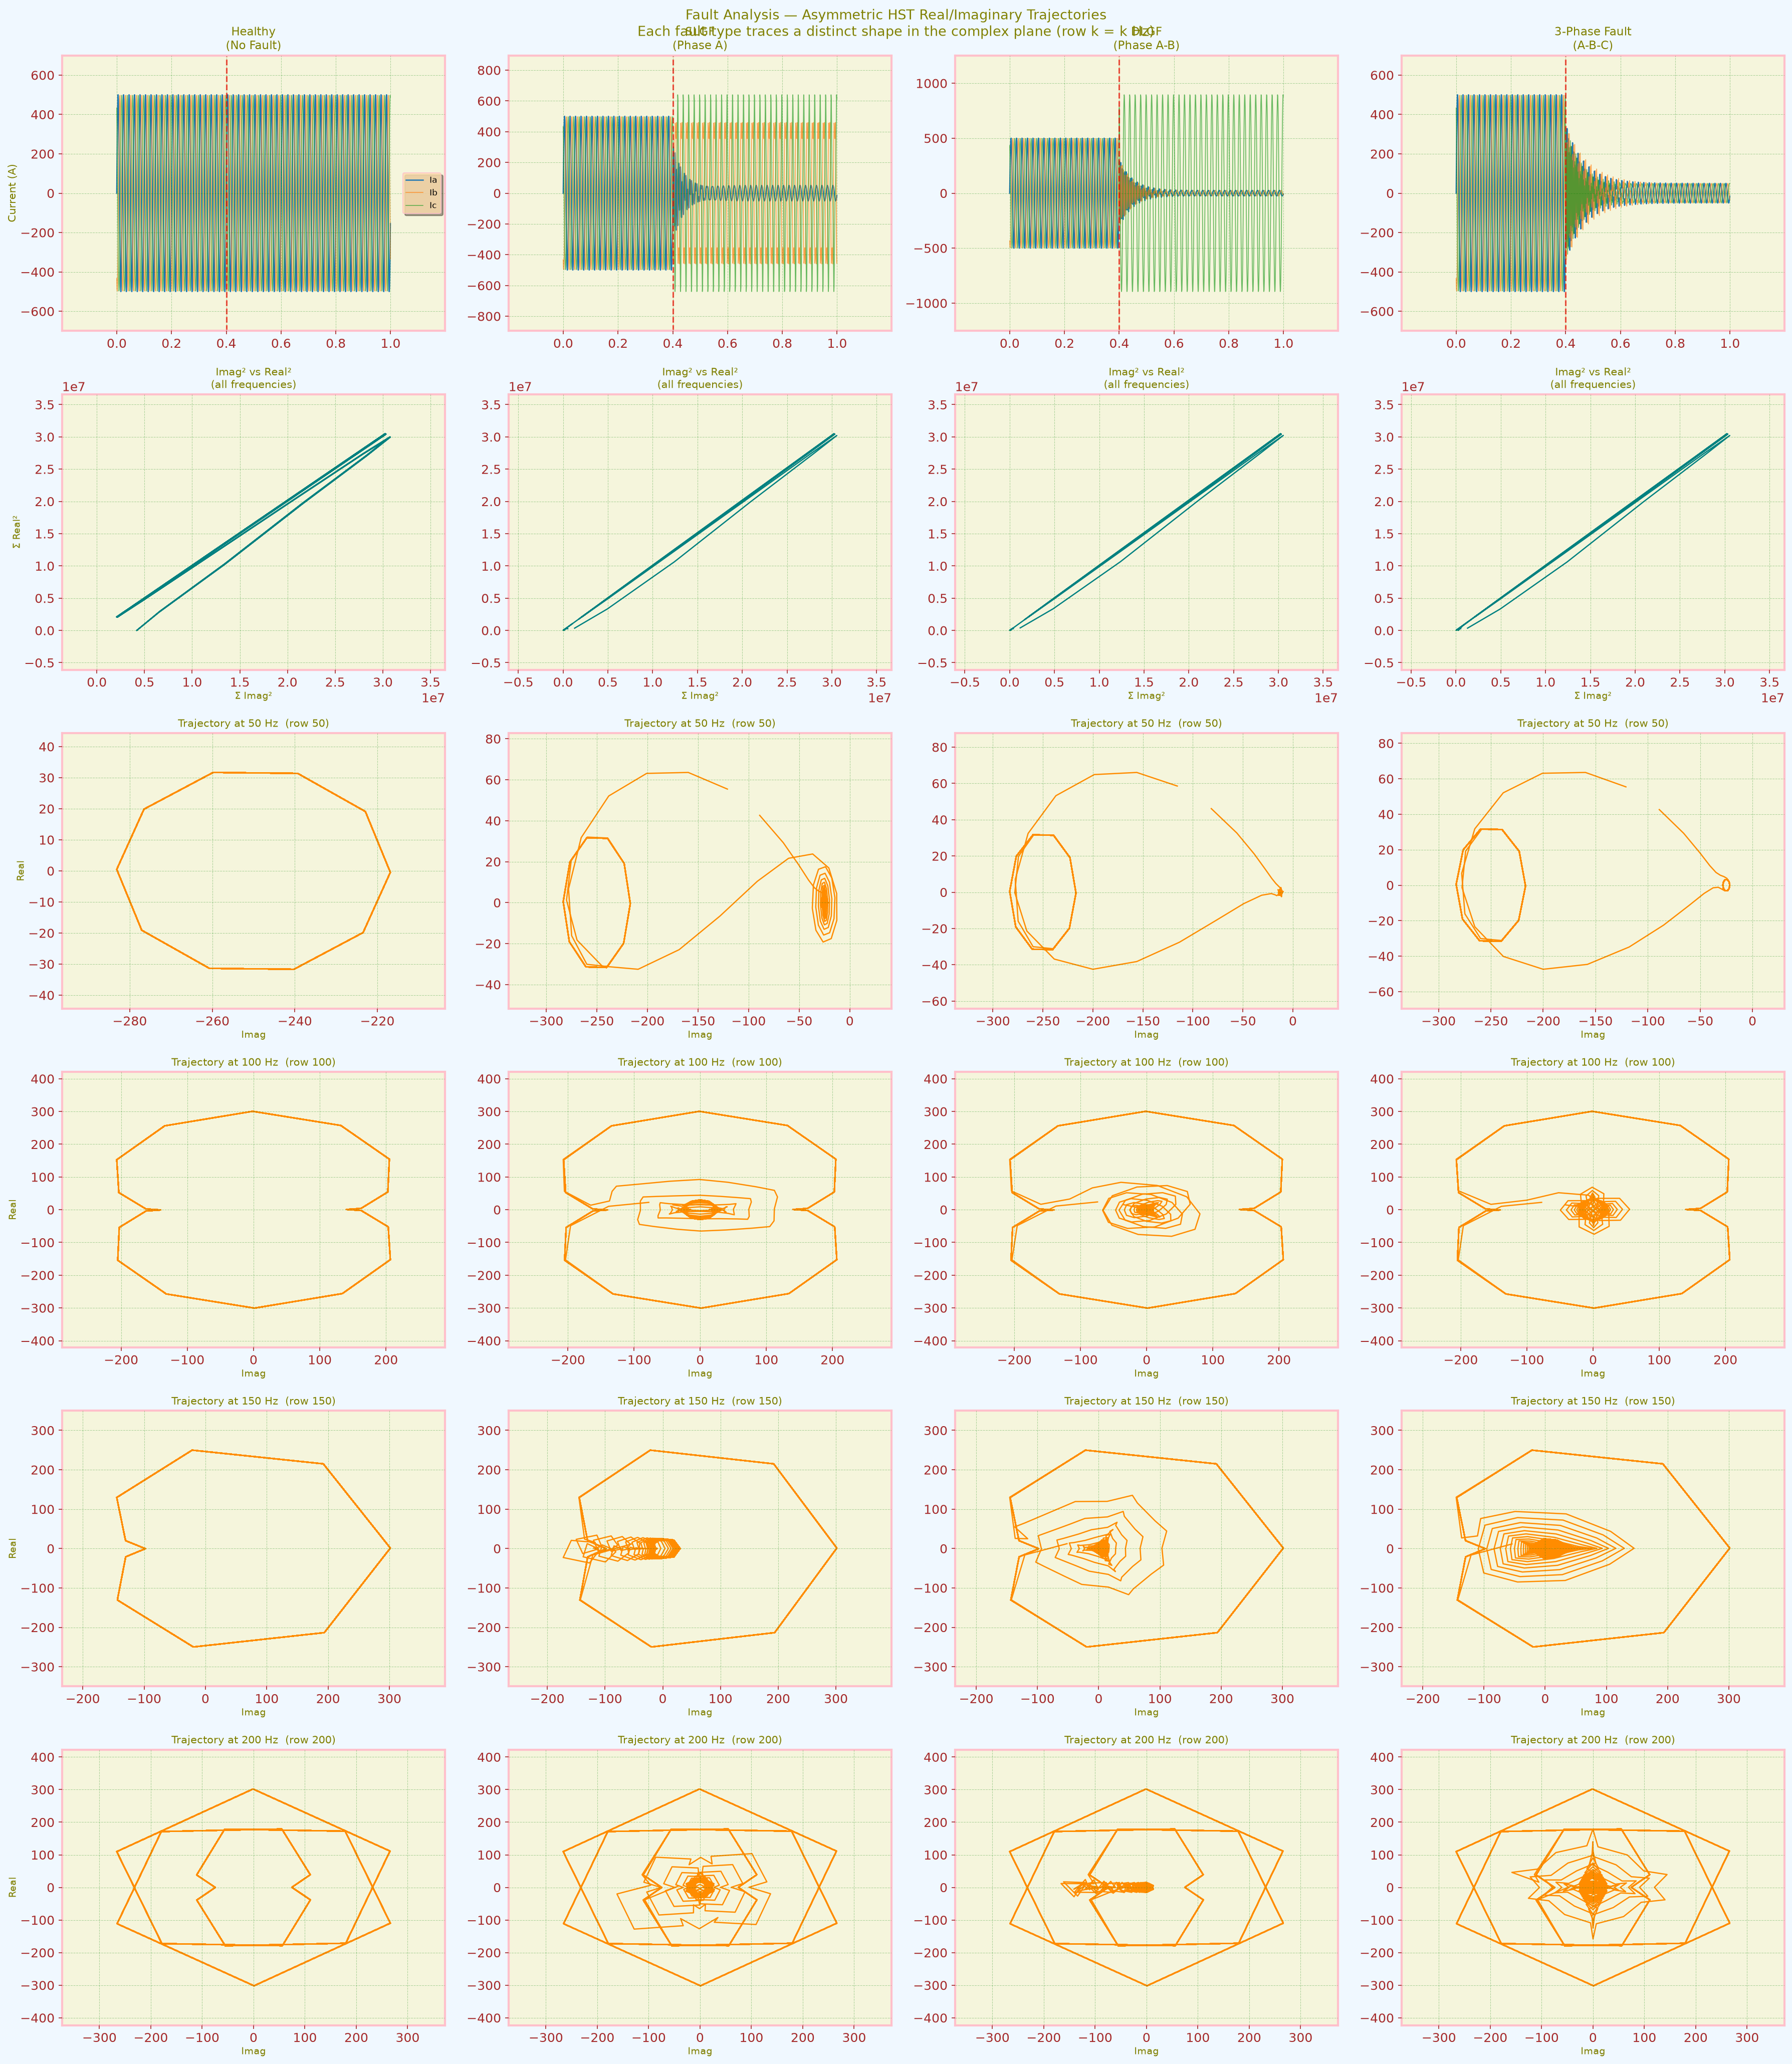

Note: 200 Hz trajectory is non-zero only in fault cases. Healthy case is near-zero.


In [ ]:
# n*dt=1.0 s → bin k = k Hz; inspect 50, 100, 150, 200 Hz rows directly
freq_list_fault = [50, 100, 150, 200]
noise_level = 0.15
signal_phase = 'Ia'

fig, axs = plt.subplots(len(freq_list_fault)+2, len(fault_data), figsize=(24, 28), sharex=False)
fig.suptitle(
    'Fault Analysis — Asymmetric HST Real/Imaginary Trajectories\n'
    'Each fault type traces a distinct shape in the complex plane (row k = k Hz)',
    fontsize=13, color='Olive'
)

for i, (title, phases) in enumerate(fault_data.items()):
    signal = phases[signal_phase]
    S = st_asym.fit_transform(t_fault, signal)

    axs[0, i].plot(t_fault, phases['Ia'], lw=1.2, label='Ia')
    axs[0, i].plot(t_fault, phases['Ib'], lw=0.8, alpha=0.7, label='Ib')
    axs[0, i].plot(t_fault, phases['Ic'], lw=0.8, alpha=0.7, label='Ic')
    axs[0, i].set_title(title, fontsize=11)
    axs[0, i].axvline(t0_fault, color='red', lw=1.5, ls='--', alpha=0.7)
    if i == 0:
        axs[0, i].legend(fontsize=8)
        axs[0, i].set_ylabel('Current (A)', fontsize=10)

    axs[1, i].plot(np.sum(S.imag**2, axis=0), np.sum(S.real**2, axis=0),
                   lw=1.2, color='teal')
    axs[1, i].set_title('Imag² vs Real²\n(all frequencies)', fontsize=10)
    axs[1, i].set_xlabel('Σ Imag²', fontsize=9)
    if i == 0:
        axs[1, i].set_ylabel('Σ Real²', fontsize=9)

    for j, freq in enumerate(freq_list_fault):
        row = freq  # bin k = k Hz when n*dt=1
        if row < S.shape[0]:
            axs[j+2, i].plot(S[row, :].imag, S[row, :].real, lw=1.2, color='darkorange')
        axs[j+2, i].set_title(f'Trajectory at {freq} Hz  (row {row})', fontsize=10)
        axs[j+2, i].set_xlabel('Imag', fontsize=9)
        if i == 0:
            axs[j+2, i].set_ylabel('Real', fontsize=9)

plt.savefig('fault_trajectory.png', dpi=150, bbox_inches='tight')
plt.show()
print('Note: 200 Hz trajectory is non-zero only in fault cases. Healthy case is near-zero.')

Saved fault_trajectory_animated.gif


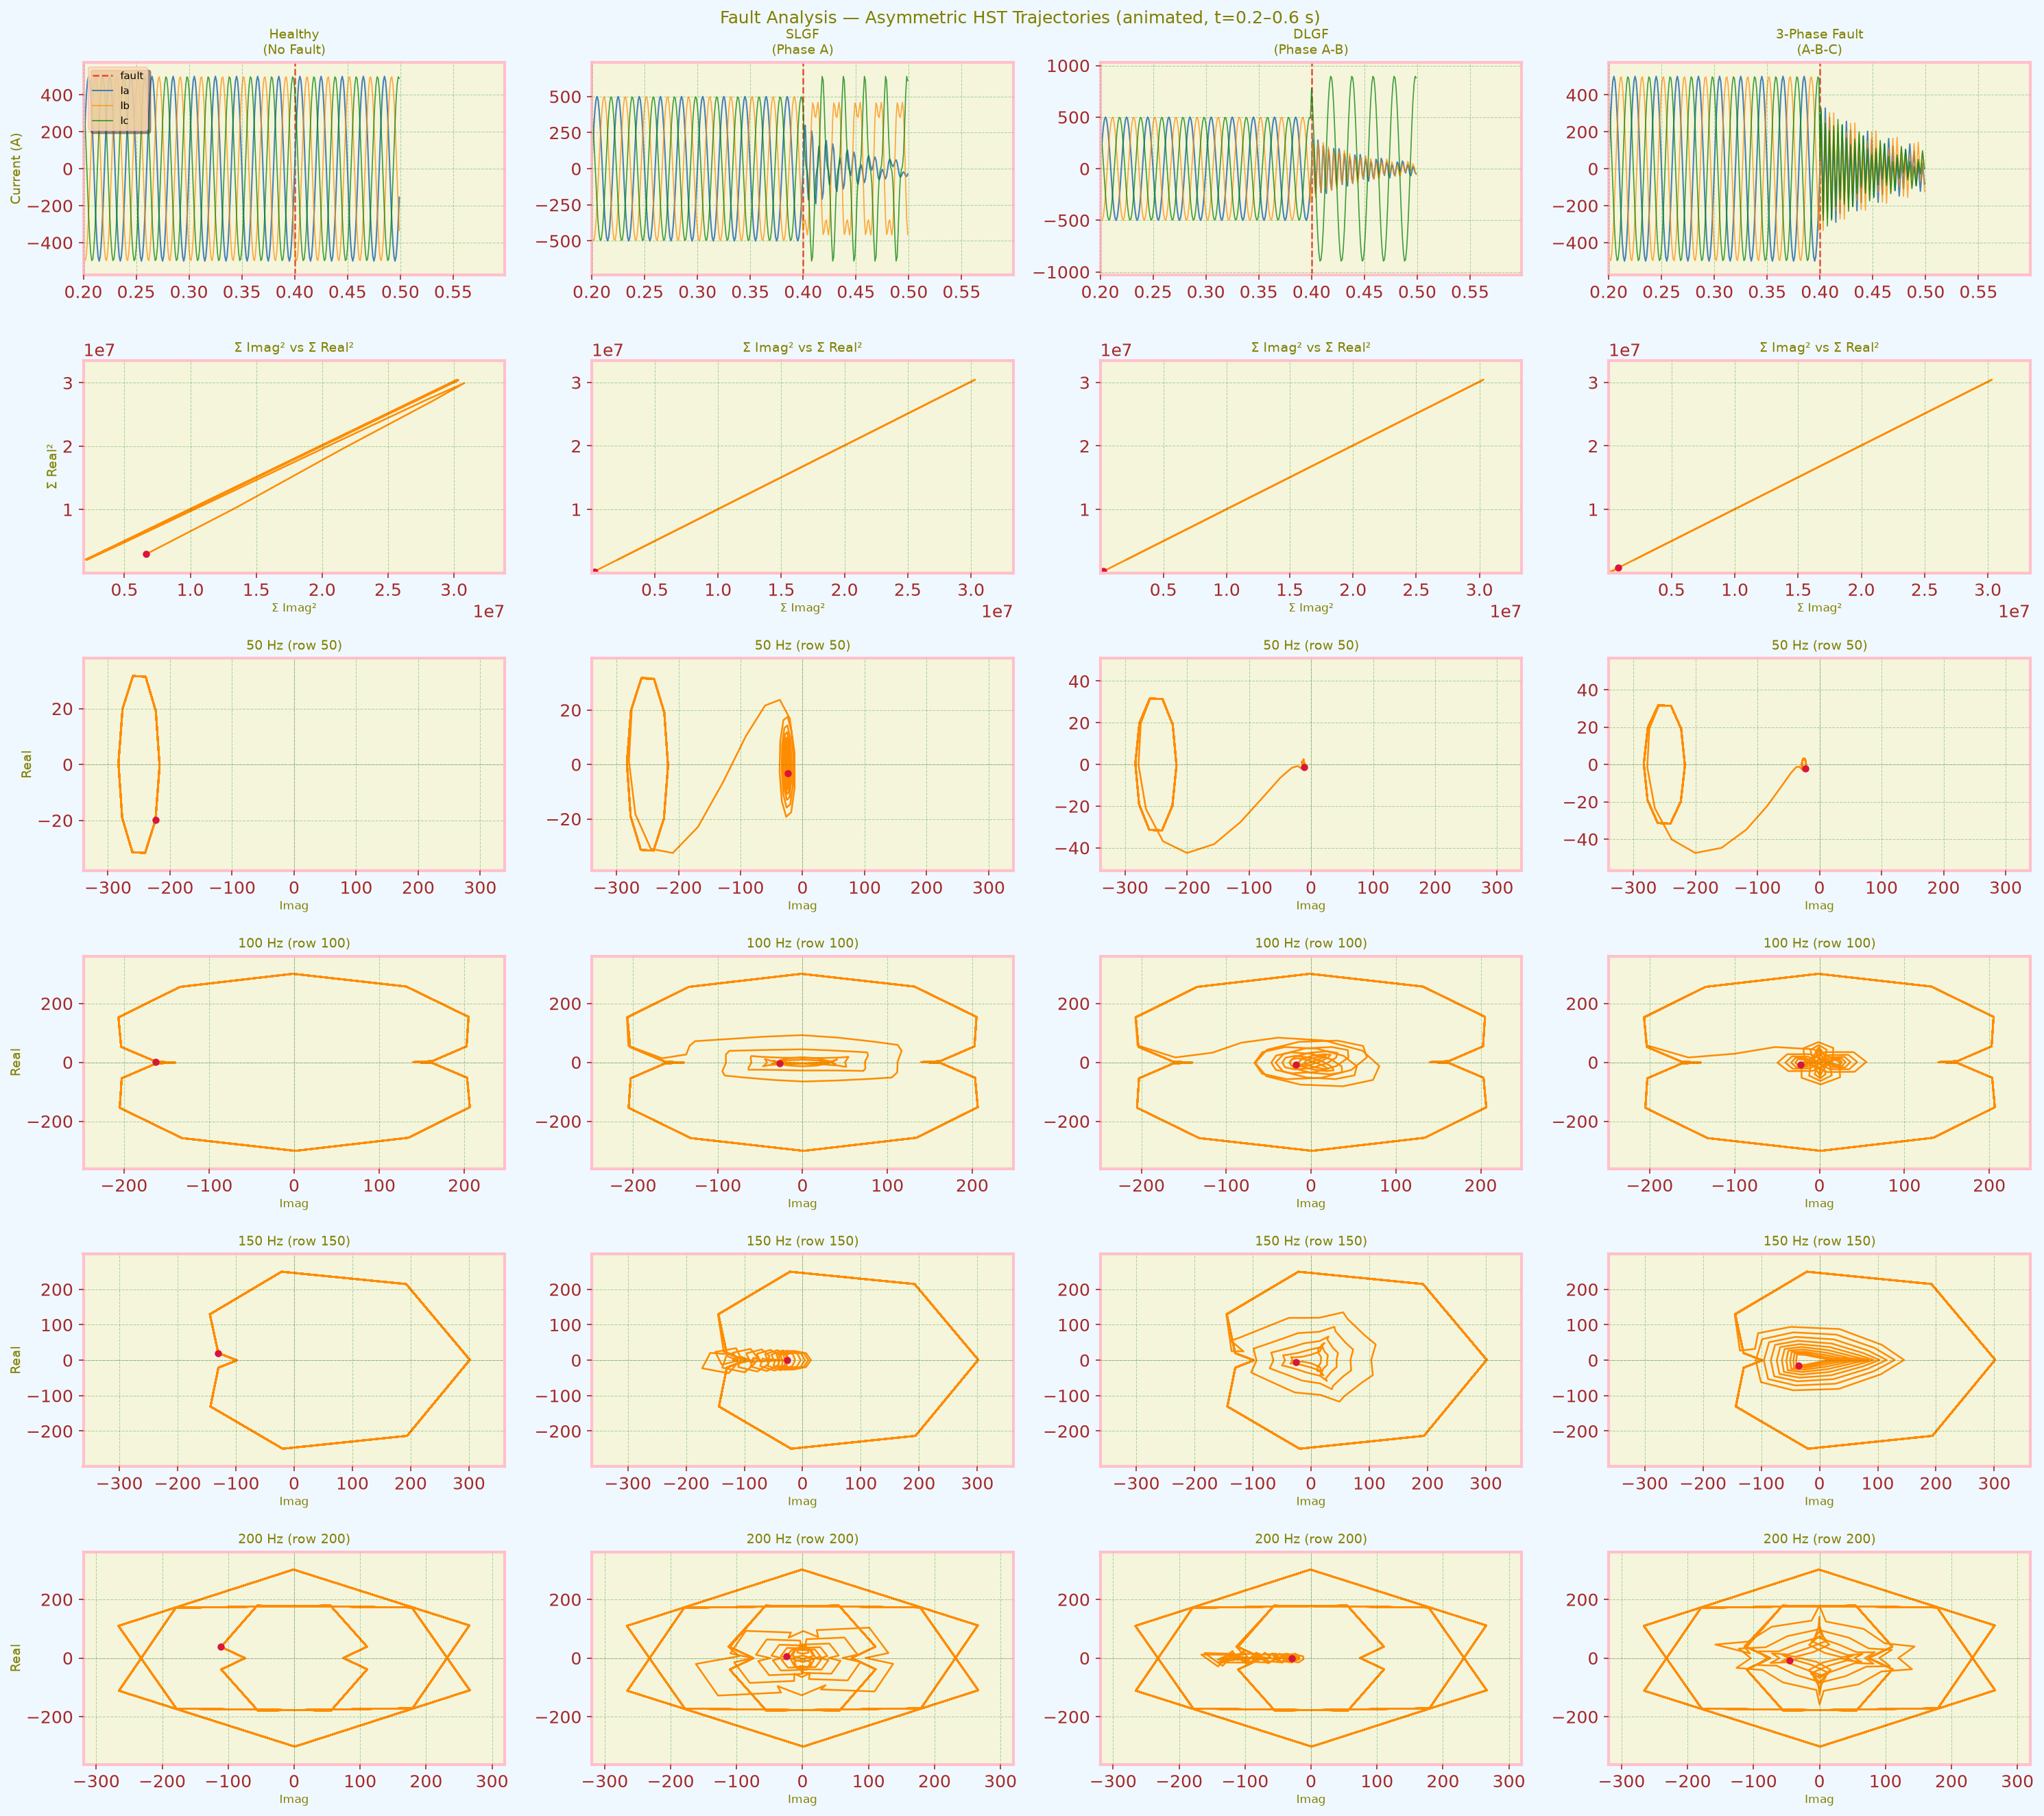

In [ ]:
# Animated fault trajectories — windowed to t=0.2→0.6 s (fault onset at 0.4 s).
# Slower playback over shorter window highlights the trajectory change at onset.
t_win_start_fa = 0.2
t_win_end_fa   = 0.6
idx_s_fa = int(t_win_start_fa * fs_fault)
idx_e_fa = int(t_win_end_fa   * fs_fault)
t_win_fa = t_fault[idx_s_fa:idx_e_fa]
n_win_fa = len(t_win_fa)

n_frames_fa = 300
step_fa     = max(1, n_win_fa // n_frames_fa)

n_rows_fa = 2 + len(freq_list_fault)
fig_fa, axs_fa = plt.subplots(
    n_rows_fa, len(fault_data),
    figsize=(5 * len(fault_data), 3 * n_rows_fa),
)
fig_fa.suptitle(
    f'Fault Analysis — Asymmetric HST Trajectories (animated, t={t_win_start_fa}–{t_win_end_fa} s)',
    color='Olive', fontsize=12,
)

S_fault_all = {
    name: st_asym.fit_transform(t_fault, phases[signal_phase])
    for name, phases in fault_data.items()
}

sig_lines_fa  = {}
sum_lines_fa  = {}
freq_lines_fa = {}

for col, (name, phases) in enumerate(fault_data.items()):
    S = S_fault_all[name]

    # ── Row 0: all three phase currents ───────────────────────────────────
    ax = axs_fa[0, col]
    all_win = np.concatenate([
        phases['Ia'][idx_s_fa:idx_e_fa],
        phases['Ib'][idx_s_fa:idx_e_fa],
        phases['Ic'][idx_s_fa:idx_e_fa],
    ])
    ypad = max(abs(all_win)) * 1.15
    ax.set_xlim(t_win_fa[0], t_win_fa[-1])
    ax.set_ylim(-ypad, ypad)
    ax.set_title(name, fontsize=9)
    ax.axvline(t0_fault, color='red', lw=1.2, ls='--', alpha=0.7, label='fault')
    if col == 0:
        ax.set_ylabel('Current (A)', fontsize=9)
    ln_a, = ax.plot([], [], color='steelblue',  lw=1.0, label='Ia')
    ln_b, = ax.plot([], [], color='darkorange', lw=0.8, alpha=0.75, label='Ib')
    ln_c, = ax.plot([], [], color='green',      lw=0.8, alpha=0.75, label='Ic')
    if col == 0:
        ax.legend(fontsize=7, loc='upper left')
    sig_lines_fa[col] = (ln_a, ln_b, ln_c)

    # ── Row 1: Σ Imag² vs Σ Real² (windowed) ─────────────────────────────
    ax1 = axs_fa[1, col]
    sum_re = np.sum(S.real**2, axis=0)[idx_s_fa:idx_e_fa]
    sum_im = np.sum(S.imag**2, axis=0)[idx_s_fa:idx_e_fa]
    pad = 0.1
    ax1.set_xlim(sum_im.min()*(1-pad), sum_im.max()*(1+pad))
    ax1.set_ylim(sum_re.min()*(1-pad), sum_re.max()*(1+pad))
    ax1.set_title('Σ Imag² vs Σ Real²', fontsize=9)
    ax1.set_xlabel('Σ Imag²', fontsize=8)
    if col == 0:
        ax1.set_ylabel('Σ Real²', fontsize=9)
    ax1.axhline(0, color='grey', lw=0.4, ls=':')
    ax1.axvline(0, color='grey', lw=0.4, ls=':')
    ln1, = ax1.plot([], [], color='teal', lw=1.2)
    dot1, = ax1.plot([], [], 'o', ms=4, color='crimson')
    sum_lines_fa[col] = (ln1, dot1, sum_im, sum_re)

    # ── Rows 2+: frequency trajectories (windowed) ───────────────────────
    for j, freq in enumerate(freq_list_fault):
        axj = axs_fa[j+2, col]
        if freq < S.shape[0]:
            re_j = S[freq, idx_s_fa:idx_e_fa].real
            im_j = S[freq, idx_s_fa:idx_e_fa].imag
            lim_r = max(abs(re_j))*1.2 or 1.0
            lim_i = max(abs(im_j))*1.2 or 1.0
        else:
            lim_r = lim_i = 1.0
        axj.set_xlim(-lim_i, lim_i)
        axj.set_ylim(-lim_r, lim_r)
        axj.set_title(f'{freq} Hz (row {freq})', fontsize=9)
        axj.set_xlabel('Imag', fontsize=8)
        if col == 0:
            axj.set_ylabel('Real', fontsize=9)
        axj.axhline(0, color='grey', lw=0.4, ls=':')
        axj.axvline(0, color='grey', lw=0.4, ls=':')
        lnj, = axj.plot([], [], lw=1.2, color='steelblue')
        dotj, = axj.plot([], [], 'o', ms=4, color='crimson')
        freq_lines_fa[(col, j)] = (lnj, dotj, freq)

plt.tight_layout()

def _fault_anim_update(frame):
    end = min((frame + 1) * step_fa, n_win_fa)
    onset_win_idx = idx_s_fa + int((t0_fault - t_win_start_fa) * fs_fault)
    onset_win_idx -= idx_s_fa   # relative to window start
    after_onset = end > onset_win_idx
    artists = []
    for col, (name, phases) in enumerate(fault_data.items()):
        S = S_fault_all[name]

        ln_a, ln_b, ln_c = sig_lines_fa[col]
        ln_a.set_data(t_win_fa[:end], phases['Ia'][idx_s_fa:idx_s_fa+end])
        ln_b.set_data(t_win_fa[:end], phases['Ib'][idx_s_fa:idx_s_fa+end])
        ln_c.set_data(t_win_fa[:end], phases['Ic'][idx_s_fa:idx_s_fa+end])
        artists += [ln_a, ln_b, ln_c]

        ln1, dot1, sum_im, sum_re = sum_lines_fa[col]
        ln1.set_data(sum_im[:end], sum_re[:end])
        ln1.set_color('darkorange' if after_onset else 'teal')
        dot1.set_data([sum_im[end-1]], [sum_re[end-1]])
        artists += [ln1, dot1]

        for j, freq in enumerate(freq_list_fault):
            lnj, dotj, row = freq_lines_fa[(col, j)]
            if row < S.shape[0]:
                S_win = S[row, idx_s_fa:idx_e_fa]
                lnj.set_data(S_win[:end].imag, S_win[:end].real)
                lnj.set_color('darkorange' if after_onset else 'steelblue')
                dotj.set_data([S_win[end-1].imag], [S_win[end-1].real])
            artists += [lnj, dotj]
    return artists

anim_fault_full = FuncAnimation(
    fig_fa, _fault_anim_update,
    frames=n_frames_fa, interval=120, blit=True,
)
anim_fault_full.save('./fault_trajectory_animated.gif', writer=PillowWriter(fps=8))
print('Saved fault_trajectory_animated.gif')
plt.show()


---
## Part 3 — Asymmetric window demo

Shows the hyperbolic asymmetry in action: an impulse at t=0 with `forwardtaper ≠ backwardtaper`.  
Uses `curvature=0.01` so asymmetry is active for the time scale used here.

In [ ]:
n_imp = 512
t_imp = np.linspace(-1, 1, n_imp, endpoint=False)  # endpoint-exclusive: dt=2/512, midpoint at 0.0
impulse = np.zeros(n_imp)
impulse[n_imp // 2] = 1.0

# ── Data-quality validation ───────────────────────────────────────────────────
# Impulse must be a unit spike at index n//2 and zero everywhere else.
assert impulse[n_imp // 2] == 1.0, "Impulse amplitude must be exactly 1.0"
assert float(np.sum(impulse)) == 1.0, "Impulse must have exactly one non-zero sample"
assert float(np.sum(impulse != 0)) == 1.0, "Impulse must have exactly one non-zero sample"
# Time axis must be endpoint-exclusive with correct spacing
_dt_imp = 2.0 / n_imp
assert abs(t_imp[1] - t_imp[0] - _dt_imp) < 1e-12, \
    f"t_imp spacing {t_imp[1]-t_imp[0]:.6f} != expected {_dt_imp:.6f}"
assert abs(t_imp[-1] - (1.0 - _dt_imp)) < 1e-10, \
    "t_imp last sample must be 1 - dt (endpoint-exclusive)"
print("Impulse signal data-quality checks passed.")

lf, lb = 0.4, 0.1   # forward taper 4× wider than backward

st_sym  = HSTransform(forwardtaper=0.25, backwardtaper=0.25, curvature=0.01)
st_asym = HSTransform(forwardtaper=lf,   backwardtaper=lb,   curvature=0.01)

S_sym  = st_sym.fit_transform(t_imp,  impulse, fsamplingrate=5)
S_asym = st_asym.fit_transform(t_imp, impulse, fsamplingrate=5)

row = 10   # frequency row to inspect

fig, axs = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Asymmetric vs Symmetric Window — Impulse Response', color='Olive')

axs[0].plot(t_imp, impulse, color='steelblue', lw=1.5)
axs[0].set_title('Input: unit impulse at t=0')
axs[0].set_xlabel('Time')

axs[1].plot(t_imp, np.abs(S_sym[row, :]),  lw=1.5, label=f'Symmetric (λf=λb=0.25)', color='teal')
axs[1].plot(t_imp, np.abs(S_asym[row, :]), lw=1.5, label=f'Asymmetric (λf={lf}, λb={lb})', color='darkorange', ls='--')
axs[1].set_title(f'|S(τ, {row})| — magnitude at freq row {row}')
axs[1].set_xlabel('Time')
axs[1].legend()

mid = n_imp // 2
axs[2].semilogy(t_imp[mid:],  np.abs(S_sym[row,  mid:]) + 1e-10, lw=1.5, label='Symmetric', color='teal')
axs[2].semilogy(t_imp[mid:],  np.abs(S_asym[row, mid:]) + 1e-10, lw=1.5, label='Asym forward', color='darkorange')
axs[2].semilogy(-t_imp[:mid][::-1], np.abs(S_asym[row, :mid])[::-1] + 1e-10,
                lw=1.5, ls='--', color='purple', label='Asym backward')
axs[2].set_title('Decay profile (log scale)\nasym forward vs backward')
axs[2].set_xlabel('|Time from impulse|')
axs[2].legend()

fig.savefig('./asymmetric_window_demo.png', dpi=100, bbox_inches='tight')
plt.show()
print(f'λf={lf} (forward/anti-causal), λb={lb} (backward/causal).')
print('Larger λ → slower decay → wider window side.')
